In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 512     # Increased batch size for better training stability
EPOCHS = 200          # More epochs for better convergence
LOG_INTERVAL = 50     # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
LATENT_DIM = 256
HIDDEN_DIM = 4096
COUPLING_HIDDEN_DIM = 512
N_COUPLE_LAYERS = 8

# VAE-specific hyperparameters
LR = 5e-4             # Lower learning rate for more stable training
BETA = 0.8            # Reduced beta to prevent posterior collapse
BETA_WARMUP = 50      # Epochs to gradually increase beta
WEIGHT_DECAY = 1e-5   # L2 regularization

# Visualization settings
SAVE_PLT_INTERVAL = 10  # How often to save plots (every 10 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE} (increased for stability)")
print(f"Epochs: {EPOCHS} (more epochs for convergence)")
print(f"Hidden dimension: {HIDDEN_DIM} (larger capacity)")
print(f"Latent dimension: {LATENT_DIM} (increased for better representation)")
print(f"Learning rate: {LR} (lower for stability)")
print(f"Beta (KL weight): {BETA} (reduced to prevent collapse)")
print(f"Beta warmup epochs: {BETA_WARMUP}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Device: {device}")


Batch size: 512 (increased for stability)
Epochs: 200 (more epochs for convergence)
Hidden dimension: 4096 (larger capacity)
Latent dimension: 256 (increased for better representation)
Learning rate: 0.0005 (lower for stability)
Beta (KL weight): 0.8 (reduced to prevent collapse)
Beta warmup epochs: 50
Weight decay: 1e-05
Device: cuda


In [3]:
train_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)


print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")


Batch size: 512
Training batches: 118
Test batches: 20


In [5]:
class CouplingLayer(nn.Module):
    """
    A coupling layer that transforms data using neural networks.

    The key idea:
    - Split input x into two parts using a mask
    - Transform one part based on the other part
    - Combine them back together
    """

    def __init__(self, input_dim, output_dim, hid_dim, mask):
        super().__init__()

        # The mask determines which dimensions to transform
        # mask = [0, 1] means: don't transform dimension 0, transform dimension 1
        self.register_buffer("mask", mask, persistent=False)

        # Neural networks to compute scaling (s) and translation (t) factors
        # These networks take the "untransformed" part and predict how to transform the other part

        # Scaling network (s): predicts how much to scale each dimension
        self.s_fc1 = nn.Linear(input_dim, hid_dim)
        self.s_fc2 = nn.Linear(hid_dim, hid_dim)
        self.s_fc3 = nn.Linear(hid_dim, hid_dim)
        self.s_fc4 = nn.Linear(hid_dim, output_dim)

        # Translation network (t): predicts how much to shift each dimension
        self.t_fc1 = nn.Linear(input_dim, hid_dim)
        self.t_fc2 = nn.Linear(hid_dim, hid_dim)
        self.t_fc3 = nn.Linear(hid_dim, hid_dim)
        self.t_fc4 = nn.Linear(hid_dim, output_dim)

    def forward(self, x):
        """
        Transform x to y using the coupling layer.
        Returns: y (transformed data) and log_det_jacobian (for computing likelihood)
        """
        # Apply mask to get the "untransformed" part
        x_m = x * self.mask

        # Compute scaling and translation factors from the untransformed part
        s_out = torch.tanh(self.s_fc4(F.relu(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(x_m))))))))
        t_out = self.t_fc4(F.relu(self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(x_m)))))))

        # Apply the transformation: y = x_m + (1-mask) * (x * exp(s) + t)
        # This means: keep the masked part unchanged, transform the unmasked part
        y = x_m + (1 - self.mask) * (x * torch.exp(s_out) + t_out)

        # Compute log determinant of Jacobian (needed for likelihood computation)
        log_det_jacobian = s_out.sum(dim=1)

        return y, log_det_jacobian

    def backward(self, y):
        """
        Reverse transformation: convert y back to x.
        This is what makes the flow invertible!
        """
        # Apply mask to get the "untransformed" part
        y_m = y * self.mask

        # Compute scaling and translation factors
        s_out = torch.tanh(self.s_fc4(F.relu(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(y_m))))))))

        t_out = self.t_fc4(F.relu(self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(y_m)))))))

        # Reverse the transformation: x = y_m + (1-mask) * (y - t) * exp(-s)
        x = y_m + (1 - self.mask) * (y - t_out) * torch.exp(-s_out)

        return x


In [6]:
class VAE(nn.Module):
    """
    Variational Autoencoder with better architecture and training stability.
    """
    
    def __init__(self, input_dim, latent_dim, hidden_dim, coupling_hid_dim, mask, n_layers=6):
        super().__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim

        self.coupling_layers = nn.ModuleList()

        # First layer uses the given mask
        self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, mask))

        # Middle layers alternate the mask pattern
        # This ensures all dimensions get transformed
        for _ in range(n_layers - 2):
            mask = 1 - mask  # Flip the mask
            self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, mask))

        # Last layer uses the opposite mask
        self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, 1 - mask))
        
        # Encoder network with batch normalization and dropout
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),

            nn.Linear(hidden_dim // 2, latent_dim),
        )
        
        # Encoder outputs (mean and log variance)
        self.fc_mu = nn.Linear(latent_dim, latent_dim)
        self.fc_logvar = nn.Linear(latent_dim, latent_dim)
        
        # Decoder network with batch normalization and dropout
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),

            nn.Linear(latent_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, input_dim),
        )
        
        # Initialize weights properly
        self._initialize_weights()
    
    def _initialize_weights(self):
        """Initialize network weights for better training."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def encode(self, x):
        """
        Encode input data into latent space.
        
        Args:
            x: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        x = self.encoder(x)

        for coupling_layer in self.coupling_layers:
            x, _ = coupling_layer(x)

        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        # Clamp logvar to prevent numerical instability
        logvar = torch.clamp(logvar, min=-10, max=10)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick for sampling from latent distribution.
        
        Args:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        
        Returns:
            z: Sampled latent vector
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        """
        Decode latent vector back to data space.
        
        Args:
            z: Latent vector of shape (batch_size, latent_dim)
        
        Returns:
            reconstructed: Reconstructed data
        """

        for coupling_layer in reversed(self.coupling_layers):
            z = coupling_layer.backward(z)

        return self.decoder(z)
    
    def forward(self, x):
        """
        Forward pass through the VAE.
        
        Args:
            x: Input data tensor
        
        Returns:
            reconstructed: Reconstructed data
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar


In [7]:
mask = torch.from_numpy(np.concat([np.zeros(LATENT_DIM // 2), np.ones(LATENT_DIM // 2)]).astype(np.float32))

# Initialize model
vae = VAE(INPUT_DIM, LATENT_DIM, HIDDEN_DIM, COUPLING_HIDDEN_DIM, mask, N_COUPLE_LAYERS)

# Move model to device
vae = vae.to(device)

# Set up optimizer with weight decay
optimizer = torch.optim.Adam(vae.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Learning rate scheduler for better convergence
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20
)

print(f"Model parameters: {sum(p.numel() for p in vae.parameters()):,}")
print(f"Learning rate: {LR}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Model moved to device: {device}")
print(f"Learning rate scheduler: ReduceLROnPlateau")

# Let's see what our model looks like
print("\nVAE architecture:")
print(vae)


Model parameters: 70,674,192
Learning rate: 0.0005
Weight decay: 1e-05
Model moved to device: cuda
Learning rate scheduler: ReduceLROnPlateau

VAE architecture:
VAE(
  (coupling_layers): ModuleList(
    (0-7): 8 x CouplingLayer(
      (s_fc1): Linear(in_features=256, out_features=512, bias=True)
      (s_fc2): Linear(in_features=512, out_features=512, bias=True)
      (s_fc3): Linear(in_features=512, out_features=512, bias=True)
      (s_fc4): Linear(in_features=512, out_features=256, bias=True)
      (t_fc1): Linear(in_features=256, out_features=512, bias=True)
      (t_fc2): Linear(in_features=512, out_features=512, bias=True)
      (t_fc3): Linear(in_features=512, out_features=512, bias=True)
      (t_fc4): Linear(in_features=512, out_features=256, bias=True)
    )
  )
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=4096, bias=True)
    (1): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dr

In [8]:
def vae_loss(reconstructed, original, mu, logvar, beta=1.0):
    """
    Compute the VAE loss function with better numerical stability.
    
    Args:
        reconstructed: Reconstructed data from decoder
        original: Original input data
        mu: Mean of latent distribution
        logvar: Log variance of latent distribution
        beta: Weight for KL divergence term
    
    Returns:
        total_loss: Total VAE loss
        recon_loss: Reconstruction loss
        kl_loss: KL divergence loss
    """
    # Reconstruction loss (MSE with mean reduction for better scaling)
    recon_loss = F.mse_loss(reconstructed, original, reduction='mean')
    
    # KL divergence loss with numerical stability
    # KL(q(z|x) || p(z)) where p(z) = N(0, I)
    # closed form analytical solution for KL divergence
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    
    # Total loss
    total_loss = recon_loss + beta * kl_loss
    
    return total_loss, recon_loss, kl_loss

def get_beta_schedule(epoch, max_epochs, warmup_epochs):
    """
    Get beta value with warmup schedule to prevent posterior collapse.
    
    Args:
        epoch: Current epoch
        max_epochs: Total number of epochs
        warmup_epochs: Number of epochs for warmup
    
    Returns:
        beta: Current beta value
    """
    if epoch < warmup_epochs:
        # Linear warmup from 0 to BETA
        return BETA * (epoch / warmup_epochs)
    else:
        # Cyclical annealing to prevent posterior collapse
        cycle_length = 50
        cycle_position = (epoch - warmup_epochs) % cycle_length
        cycle_progress = cycle_position / cycle_length
        return BETA * (0.5 + 0.5 * np.cos(np.pi * cycle_progress))

def train_epoch(epoch):
    """
    Train the VAE for one epoch with beta scheduling.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_total_loss: Average total loss for this epoch
        avg_recon_loss: Average reconstruction loss
        avg_kl_loss: Average KL divergence loss
        current_beta: Current beta value used
    """
    vae.train()
    
    # Get current beta value with scheduling
    current_beta = get_beta_schedule(epoch, EPOCHS, BETA_WARMUP)
    
    total_losses = []
    recon_losses = []
    kl_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Clear gradients
        optimizer.zero_grad()
        
        # Forward pass
        reconstructed, mu, logvar = vae(data)
        
        # Compute loss with current beta
        total_loss, recon_loss, kl_loss = vae_loss(reconstructed, data, mu, logvar, current_beta)
        
        # Backward pass
        total_loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Track losses
        total_losses.append(total_loss.item())
        recon_losses.append(recon_loss.item())
        kl_losses.append(kl_loss.item())
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tTotal Loss: {:.6f}\tRecon Loss: {:.6f}\tKL Loss: {:.6f}\tBeta: {:.3f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), total_loss.item(), recon_loss.item(), kl_loss.item(), current_beta))
    
    # Calculate average losses
    avg_total_loss = sum(total_losses) / len(total_losses)
    avg_recon_loss = sum(recon_losses) / len(recon_losses)
    avg_kl_loss = sum(kl_losses) / len(kl_losses)
    
    # Update learning rate scheduler
    scheduler.step(avg_total_loss)
    
    print('====> Epoch: {} Average Total Loss: {:.4f}, Average Recon Loss: {:.4f}, Average KL Loss: {:.4f}, Beta: {:.3f}'.format(
        epoch, avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta))
    
    return avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta

In [9]:
def generate_samples(num_samples=1000):
    """
    Generate new samples using the VAE decoder.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        generated_samples: Generated data as numpy array
    """
    vae.eval()
    
    with torch.no_grad():
        # Sample from standard Gaussian in latent space
        z = torch.randn(num_samples, LATENT_DIM, device=device)
        
        # Decode to generate samples
        generated_samples = vae.decode(z)
        
        # Convert to numpy for visualization
        generated_samples = generated_samples.cpu().numpy()
    
    return generated_samples

def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

def visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=False):
    """
    Visualize the current state of our VAE training.
    
    Args:
        epoch: Current epoch number
        total_losses: List of total losses
        recon_losses: List of reconstruction losses
        kl_losses: List of KL divergence losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Loss plots
    if len(total_losses) > 0:
        epochs_range = range(1, len(total_losses) + 1)
        
        # Total loss
        plt.subplot(2, 3, 4)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Total Loss')
        plt.title('Total Loss Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Reconstruction and KL losses
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=2)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Loss Components')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=1, alpha=0.7)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=1, alpha=0.7)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('All Losses Combined')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save plot if requested
    if save_plot:
        if not os.path.exists('vae_results'):
            os.makedirs('vae_results')
        plt.savefig(f'vae_results/vae_progress_epoch_{epoch}.png', dpi=150, bbox_inches='tight')
        print(f"💾 Saved plot: vae_results/vae_progress_epoch_{epoch}.png")
    
    plt.show()


🎯 Starting VAE training...
📊 Initial state (before training):
💾 Saved plot: vae_results/vae_progress_epoch_0.png


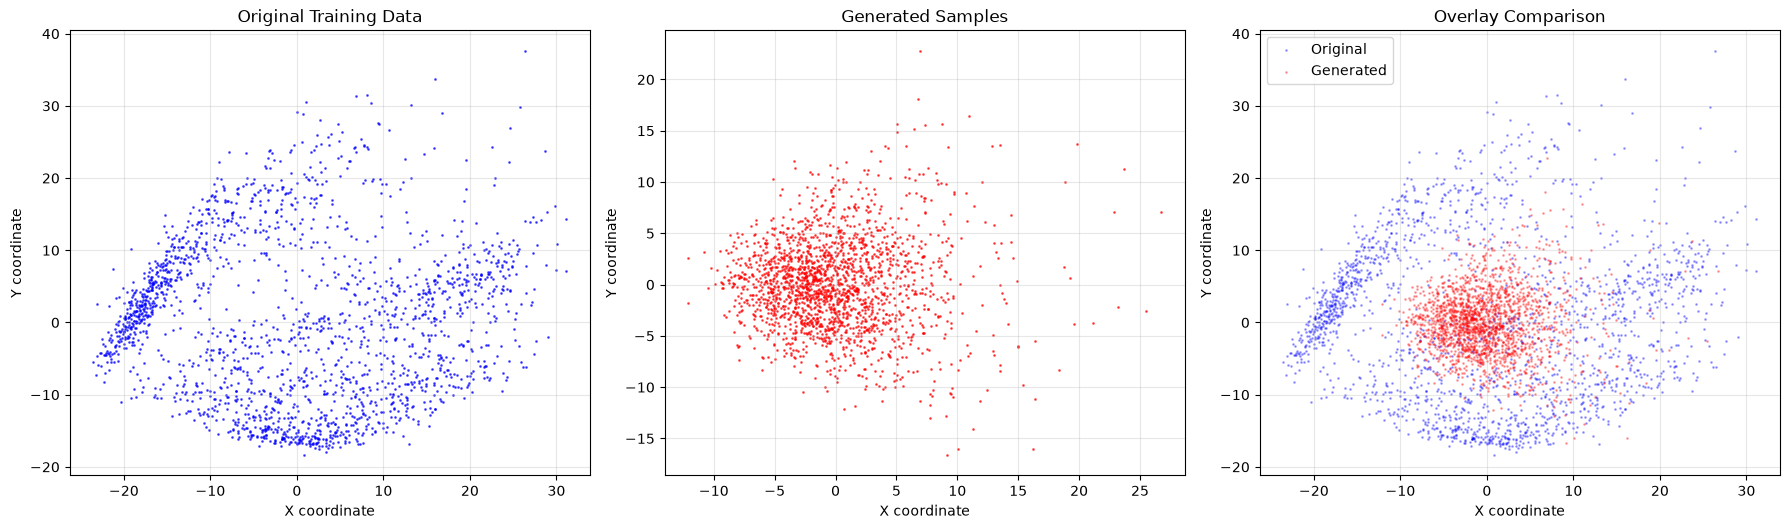


📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/60000 (0%)]	Total Loss: 1.165873	Recon Loss: 1.125602	KL Loss: 2.516893	Beta: 0.016
Epoch: 1 [25600/60000 (42%)]	Total Loss: 0.150369	Recon Loss: 0.114182	KL Loss: 2.261690	Beta: 0.016
Epoch: 1 [51200/60000 (85%)]	Total Loss: 0.075952	Recon Loss: 0.073004	KL Loss: 0.184208	Beta: 0.016
====> Epoch: 1 Average Total Loss: 0.6583, Average Recon Loss: 0.1903, Average KL Loss: 29.2521, Beta: 0.016
📈 Epoch 1 Summary:
   Total Loss: 0.6583
   Reconstruction Loss: 0.1903
   KL Divergence Loss: 29.2521
   Beta: 0.016
   Learning Rate: 0.000500

📊 Epoch 2/200
----------------------------------------
Epoch: 2 [0/60000 (0%)]	Total Loss: 0.070264	Recon Loss: 0.064488	KL Loss: 0.180497	Beta: 0.032
Epoch: 2 [25600/60000 (42%)]	Total Loss: 0.058714	Recon Loss: 0.052488	KL Loss: 0.194556	Beta: 0.032
Epoch: 2 [51200/60000 (85%)]	Total Loss: 0.054741	Recon Loss: 0.051049	KL Loss: 0.115357	Beta: 0.032
====> Epoch: 2 Average Total Loss: 0.0

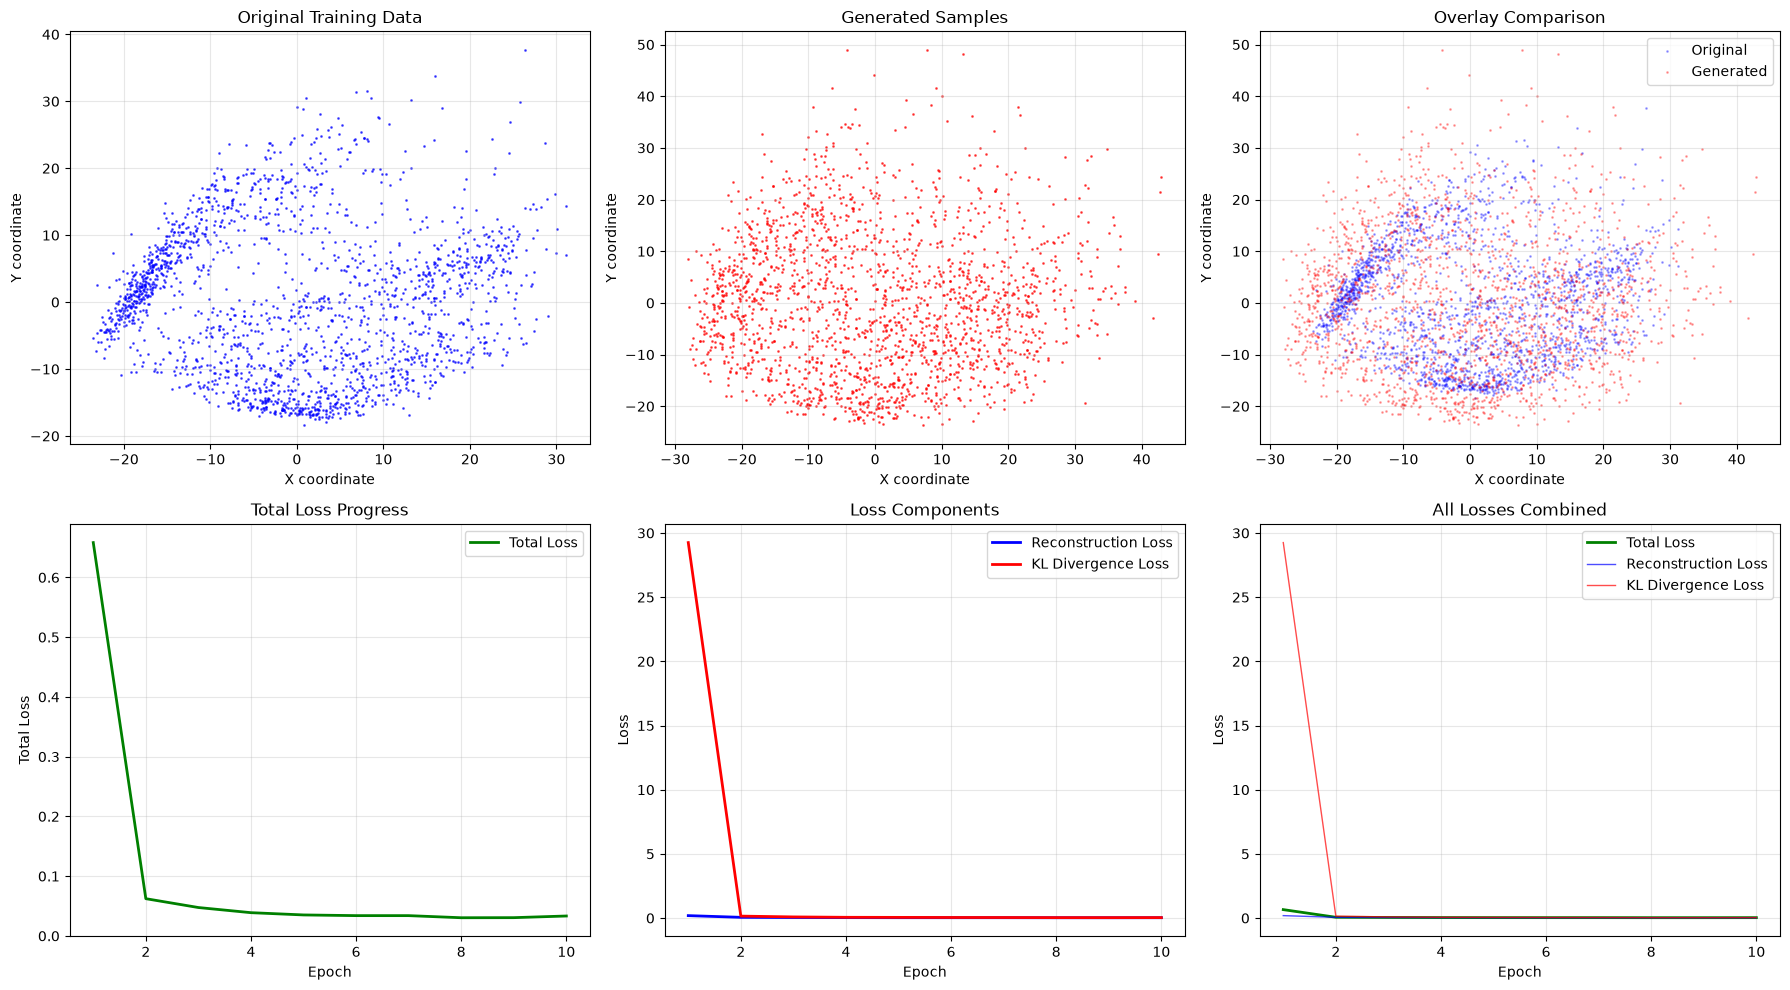

📈 Epoch 10 Summary:
   Total Loss: 0.0333
   Reconstruction Loss: 0.0274
   KL Divergence Loss: 0.0366
   Beta: 0.160
   Learning Rate: 0.000500

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/60000 (0%)]	Total Loss: 0.032082	Recon Loss: 0.026070	KL Loss: 0.034158	Beta: 0.176
Epoch: 11 [25600/60000 (42%)]	Total Loss: 0.032609	Recon Loss: 0.026765	KL Loss: 0.033205	Beta: 0.176
Epoch: 11 [51200/60000 (85%)]	Total Loss: 0.033752	Recon Loss: 0.028087	KL Loss: 0.032186	Beta: 0.176
====> Epoch: 11 Average Total Loss: 0.0319, Average Recon Loss: 0.0260, Average KL Loss: 0.0336, Beta: 0.176
📈 Epoch 11 Summary:
   Total Loss: 0.0319
   Reconstruction Loss: 0.0260
   KL Divergence Loss: 0.0336
   Beta: 0.176
   Learning Rate: 0.000500

📊 Epoch 12/200
----------------------------------------
Epoch: 12 [0/60000 (0%)]	Total Loss: 0.031315	Recon Loss: 0.025203	KL Loss: 0.031836	Beta: 0.192
Epoch: 12 [25600/60000 (42%)]	Total Loss: 0.030317	Recon Loss: 0.024594	KL Loss: 0.029810

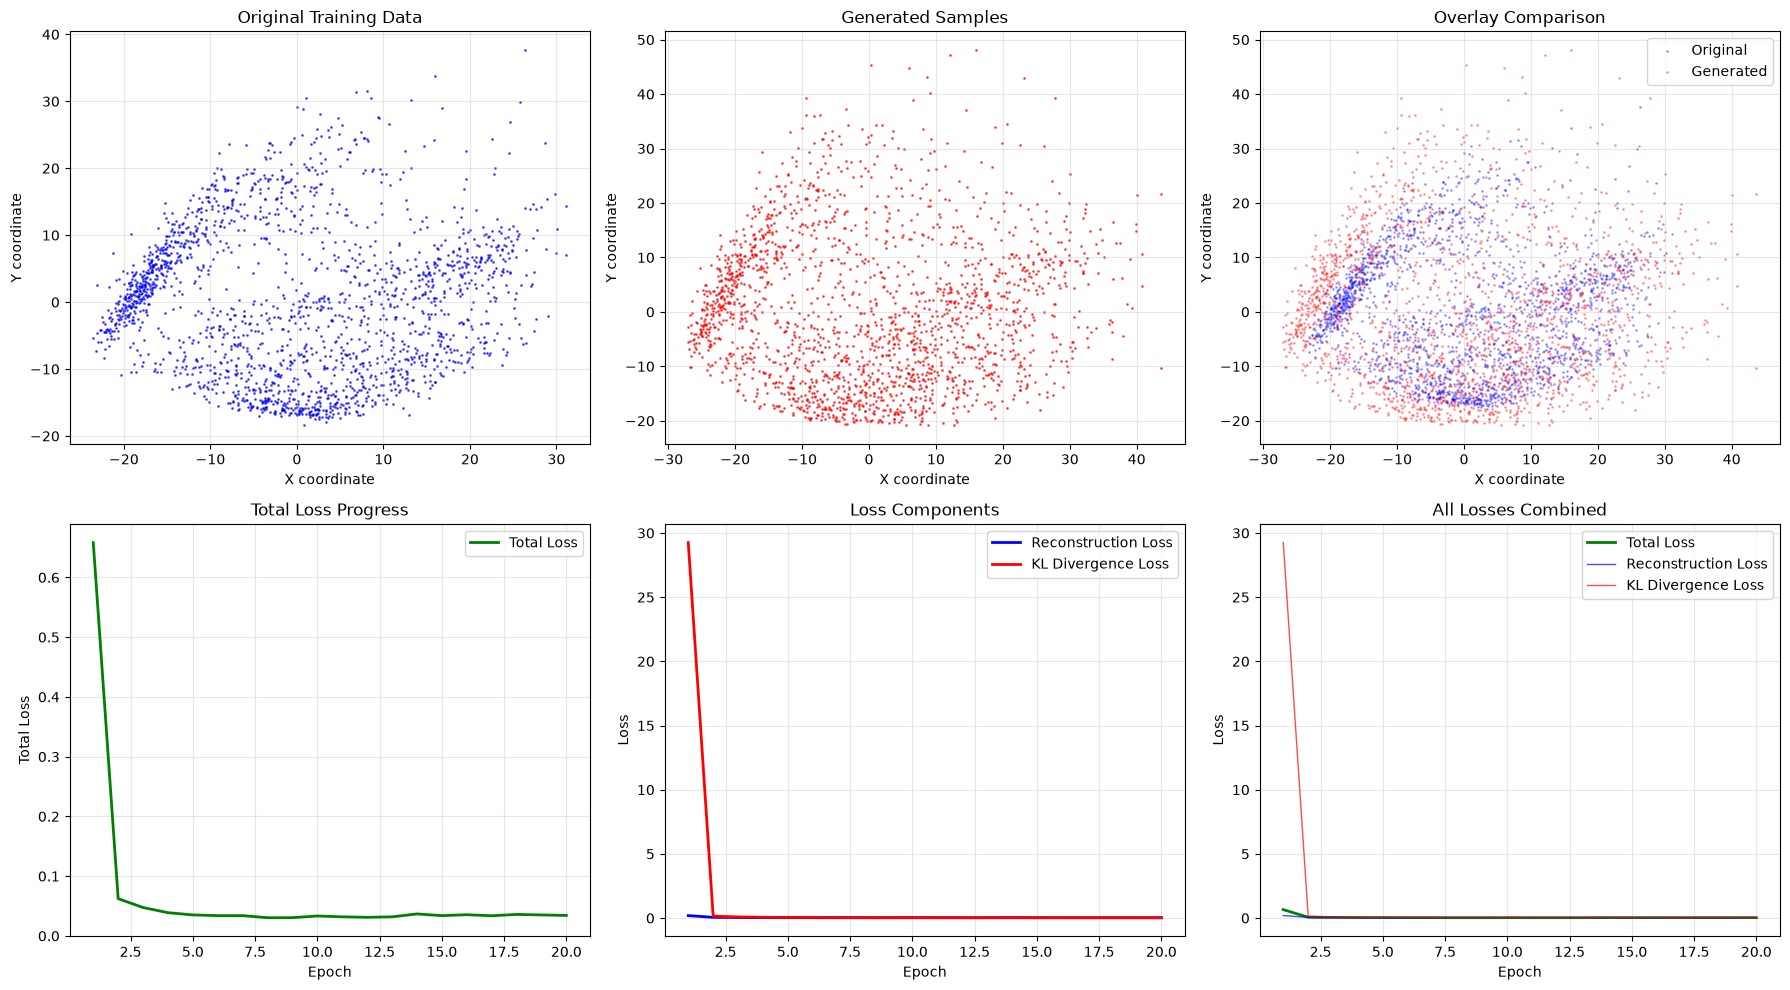

📈 Epoch 20 Summary:
   Total Loss: 0.0342
   Reconstruction Loss: 0.0259
   KL Divergence Loss: 0.0259
   Beta: 0.320
   Learning Rate: 0.000500

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/60000 (0%)]	Total Loss: 0.034678	Recon Loss: 0.025440	KL Loss: 0.027493	Beta: 0.336
Epoch: 21 [25600/60000 (42%)]	Total Loss: 0.033996	Recon Loss: 0.025217	KL Loss: 0.026126	Beta: 0.336
Epoch: 21 [51200/60000 (85%)]	Total Loss: 0.032843	Recon Loss: 0.024335	KL Loss: 0.025322	Beta: 0.336
====> Epoch: 21 Average Total Loss: 0.0352, Average Recon Loss: 0.0262, Average KL Loss: 0.0267, Beta: 0.336
📈 Epoch 21 Summary:
   Total Loss: 0.0352
   Reconstruction Loss: 0.0262
   KL Divergence Loss: 0.0267
   Beta: 0.336
   Learning Rate: 0.000500

📊 Epoch 22/200
----------------------------------------
Epoch: 22 [0/60000 (0%)]	Total Loss: 0.034165	Recon Loss: 0.025294	KL Loss: 0.025200	Beta: 0.352
Epoch: 22 [25600/60000 (42%)]	Total Loss: 0.034562	Recon Loss: 0.025777	KL Loss: 0.024959

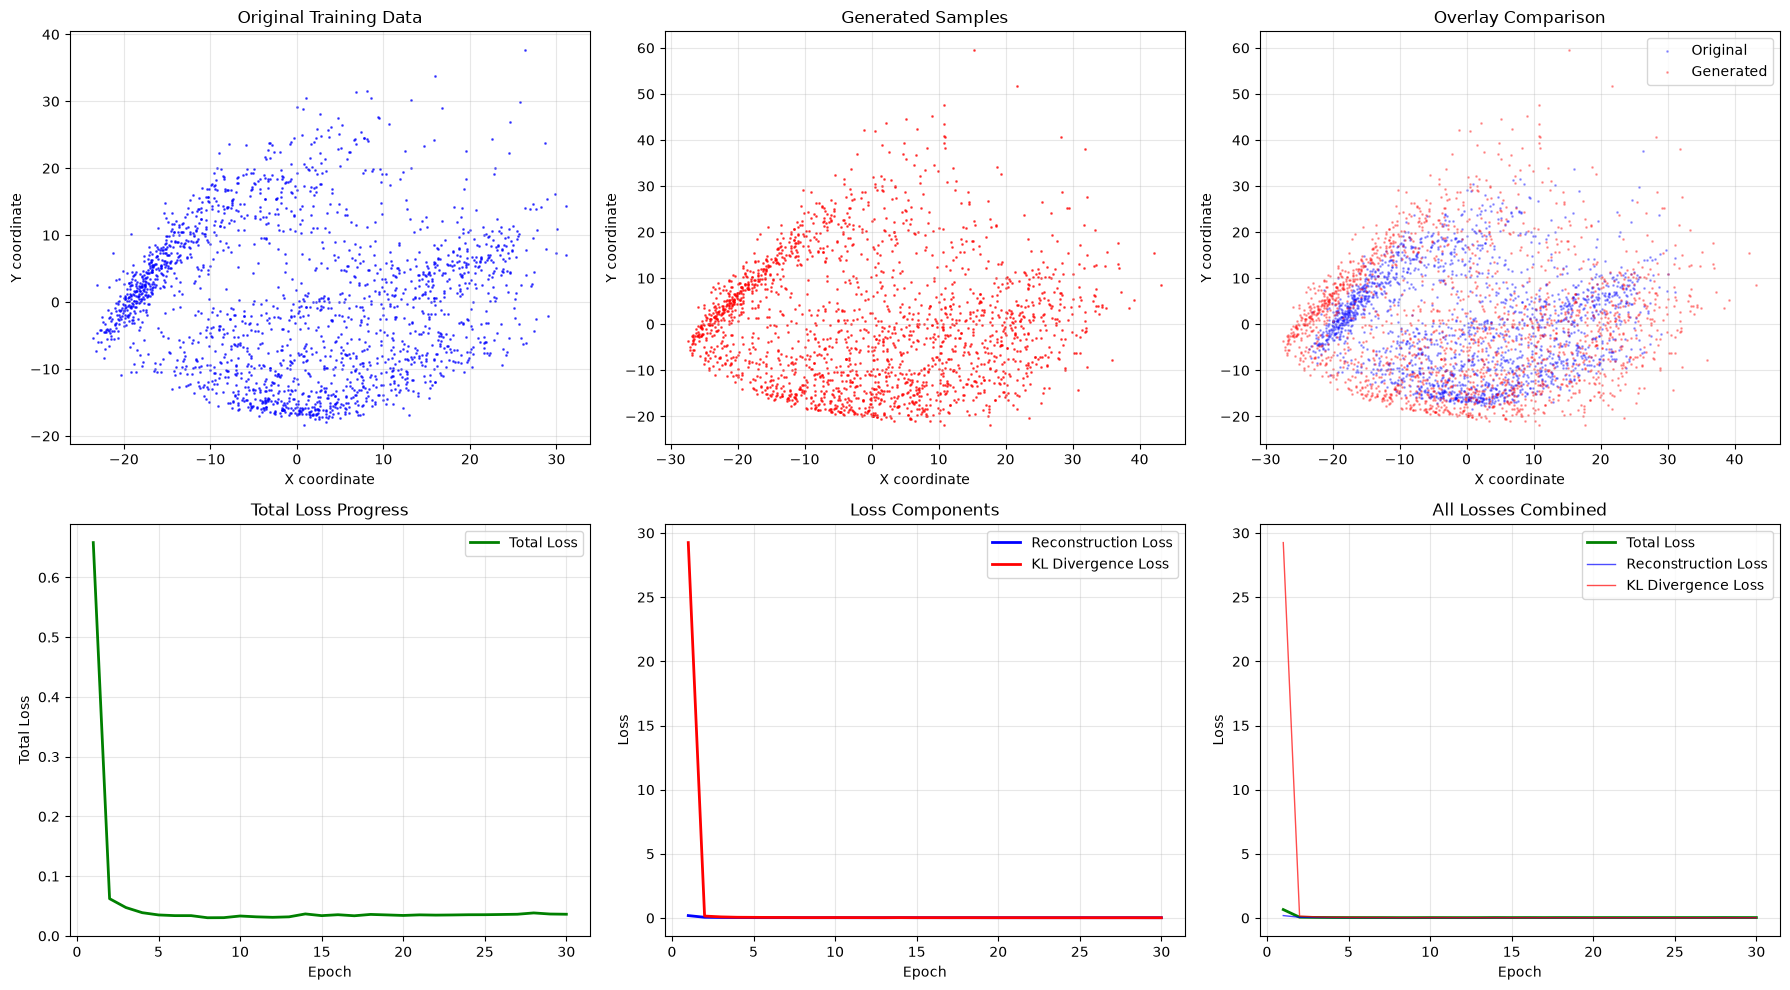

📈 Epoch 30 Summary:
   Total Loss: 0.0362
   Reconstruction Loss: 0.0256
   KL Divergence Loss: 0.0222
   Beta: 0.480
   Learning Rate: 0.000250

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/60000 (0%)]	Total Loss: 0.036838	Recon Loss: 0.025792	KL Loss: 0.022269	Beta: 0.496
Epoch: 31 [25600/60000 (42%)]	Total Loss: 0.035721	Recon Loss: 0.024636	KL Loss: 0.022349	Beta: 0.496
Epoch: 31 [51200/60000 (85%)]	Total Loss: 0.036660	Recon Loss: 0.025592	KL Loss: 0.022315	Beta: 0.496
====> Epoch: 31 Average Total Loss: 0.0366, Average Recon Loss: 0.0256, Average KL Loss: 0.0221, Beta: 0.496
📈 Epoch 31 Summary:
   Total Loss: 0.0366
   Reconstruction Loss: 0.0256
   KL Divergence Loss: 0.0221
   Beta: 0.496
   Learning Rate: 0.000250

📊 Epoch 32/200
----------------------------------------
Epoch: 32 [0/60000 (0%)]	Total Loss: 0.036869	Recon Loss: 0.025424	KL Loss: 0.022354	Beta: 0.512
Epoch: 32 [25600/60000 (42%)]	Total Loss: 0.036321	Recon Loss: 0.025084	KL Loss: 0.021948

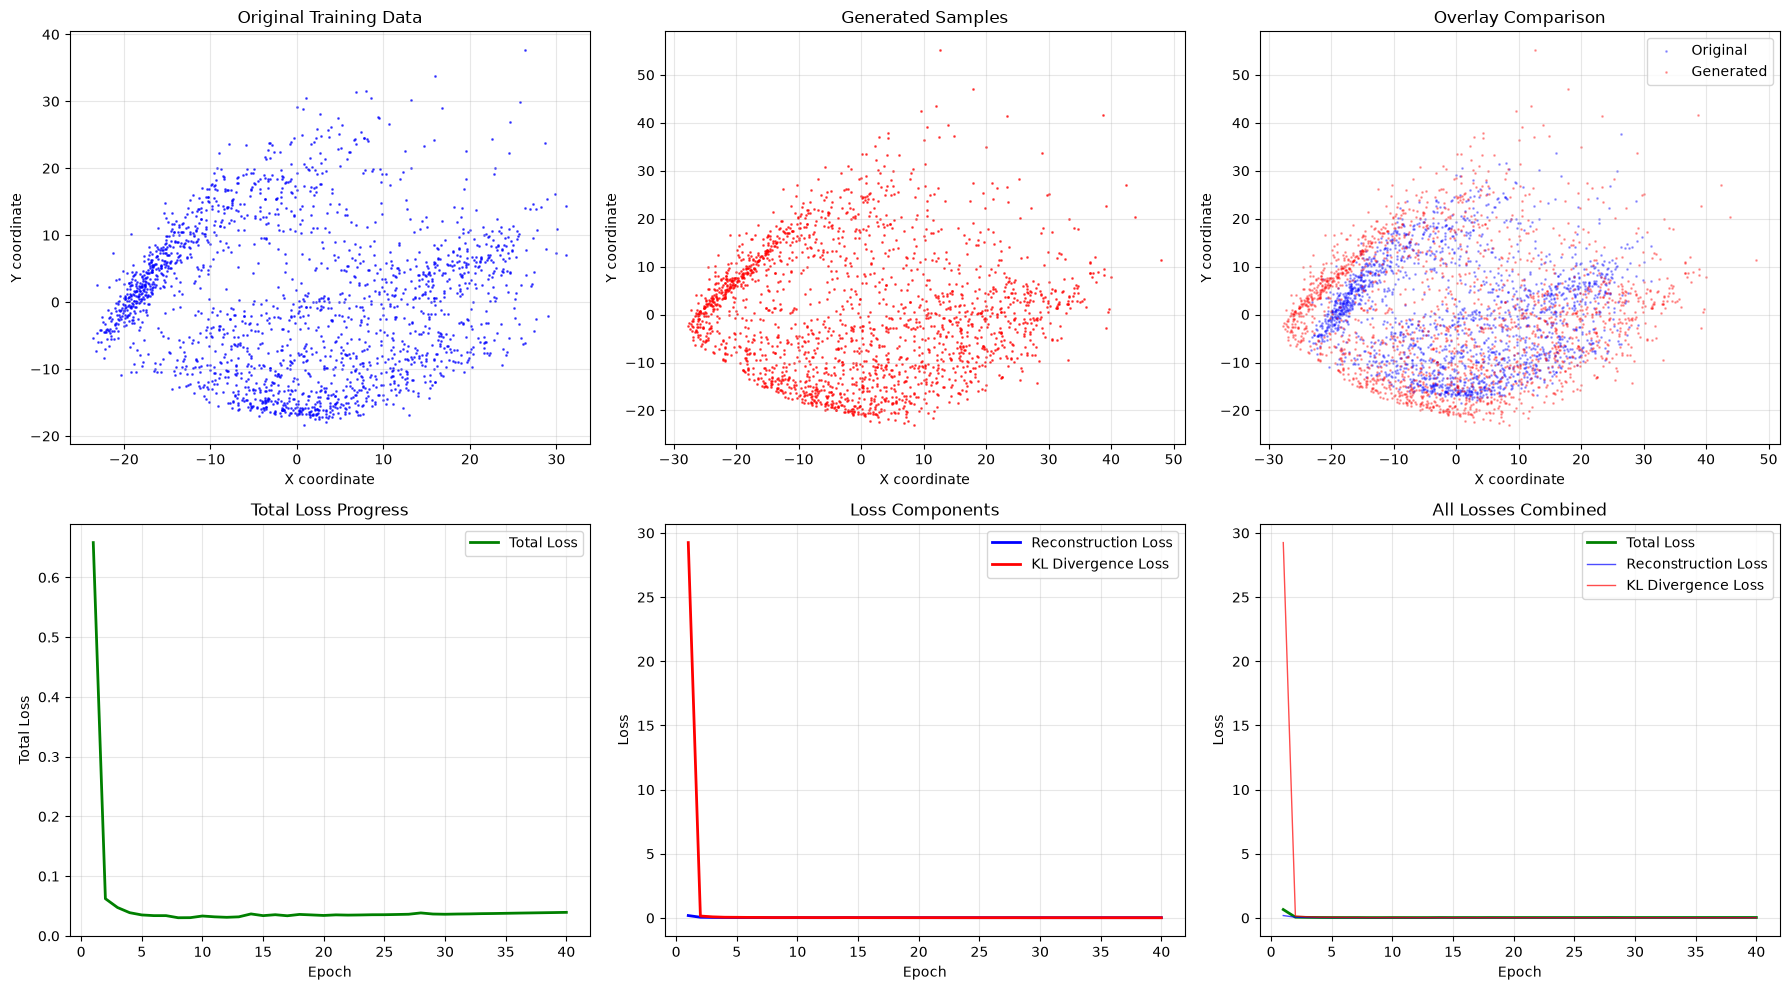

📈 Epoch 40 Summary:
   Total Loss: 0.0394
   Reconstruction Loss: 0.0268
   KL Divergence Loss: 0.0197
   Beta: 0.640
   Learning Rate: 0.000250

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/60000 (0%)]	Total Loss: 0.040150	Recon Loss: 0.027059	KL Loss: 0.019957	Beta: 0.656
Epoch: 41 [25600/60000 (42%)]	Total Loss: 0.039109	Recon Loss: 0.026534	KL Loss: 0.019169	Beta: 0.656
Epoch: 41 [51200/60000 (85%)]	Total Loss: 0.038986	Recon Loss: 0.026177	KL Loss: 0.019526	Beta: 0.656
====> Epoch: 41 Average Total Loss: 0.0396, Average Recon Loss: 0.0268, Average KL Loss: 0.0194, Beta: 0.656
📈 Epoch 41 Summary:
   Total Loss: 0.0396
   Reconstruction Loss: 0.0268
   KL Divergence Loss: 0.0194
   Beta: 0.656
   Learning Rate: 0.000250

📊 Epoch 42/200
----------------------------------------
Epoch: 42 [0/60000 (0%)]	Total Loss: 0.040336	Recon Loss: 0.027047	KL Loss: 0.019775	Beta: 0.672
Epoch: 42 [25600/60000 (42%)]	Total Loss: 0.039502	Recon Loss: 0.026947	KL Loss: 0.018682

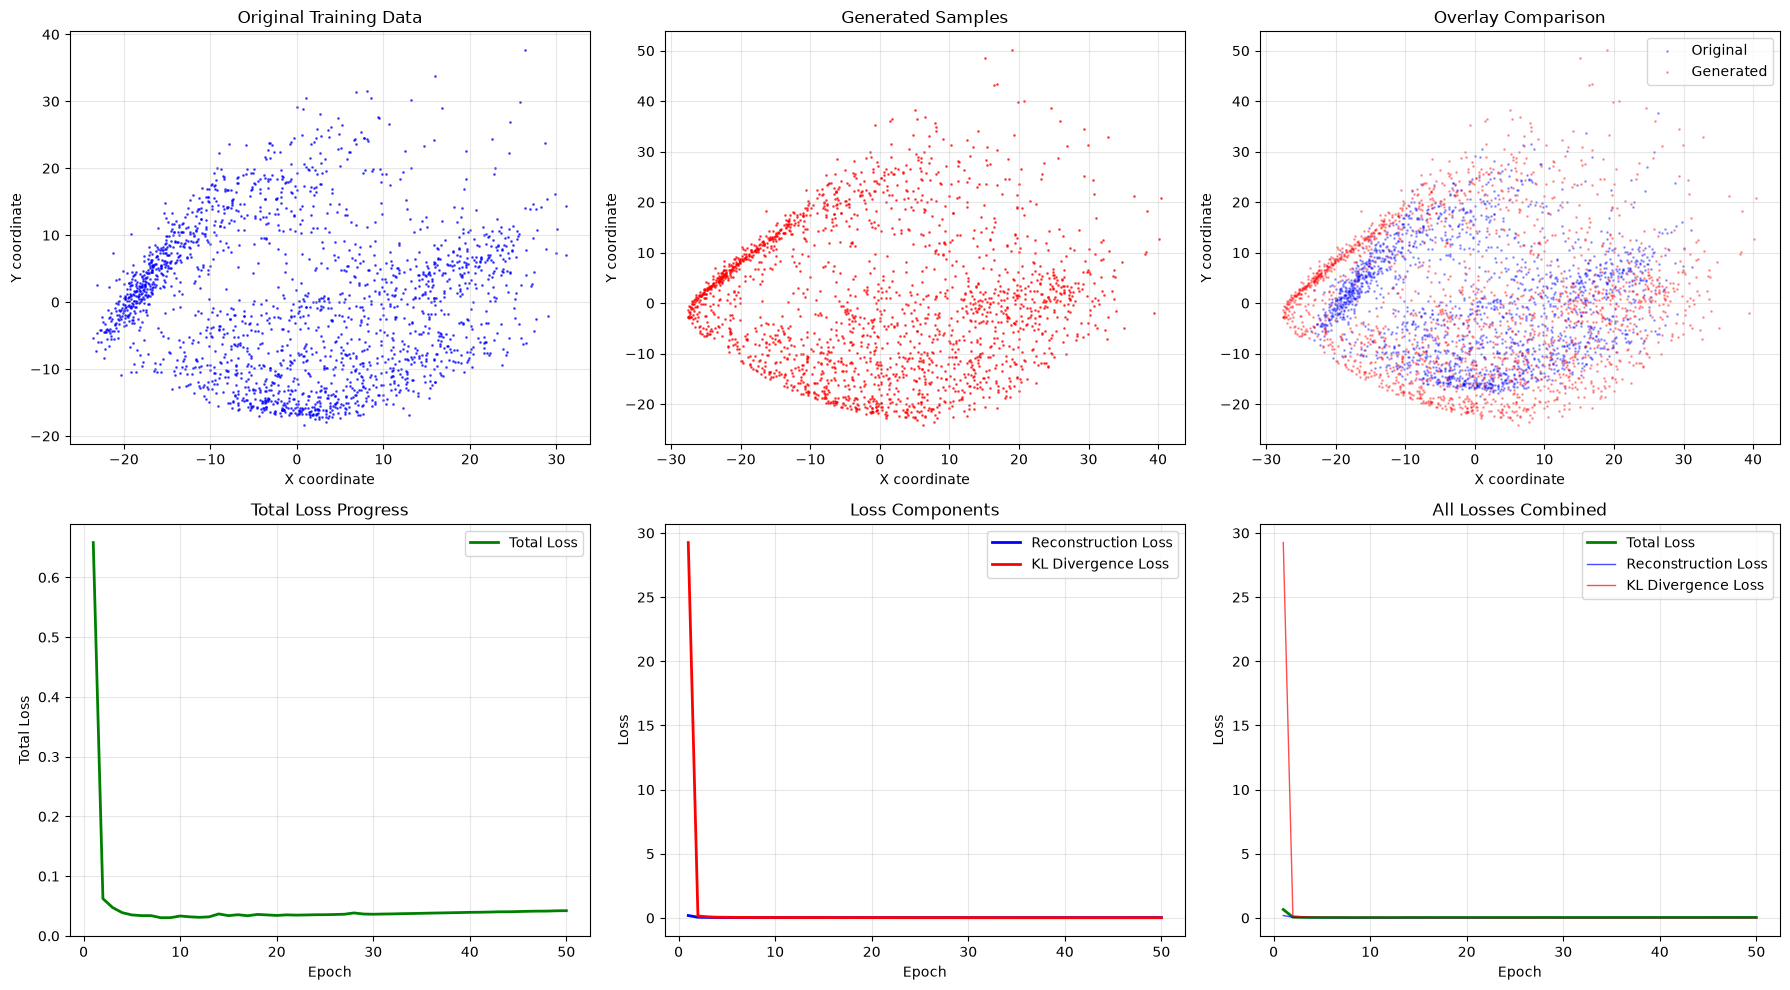

📈 Epoch 50 Summary:
   Total Loss: 0.0422
   Reconstruction Loss: 0.0281
   KL Divergence Loss: 0.0176
   Beta: 0.800
   Learning Rate: 0.000125

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/60000 (0%)]	Total Loss: 0.042034	Recon Loss: 0.028356	KL Loss: 0.017115	Beta: 0.799
Epoch: 51 [25600/60000 (42%)]	Total Loss: 0.041200	Recon Loss: 0.026849	KL Loss: 0.017957	Beta: 0.799
Epoch: 51 [51200/60000 (85%)]	Total Loss: 0.043082	Recon Loss: 0.029072	KL Loss: 0.017530	Beta: 0.799
====> Epoch: 51 Average Total Loss: 0.0417, Average Recon Loss: 0.0276, Average KL Loss: 0.0177, Beta: 0.799
📈 Epoch 51 Summary:
   Total Loss: 0.0417
   Reconstruction Loss: 0.0276
   KL Divergence Loss: 0.0177
   Beta: 0.799
   Learning Rate: 0.000125

📊 Epoch 52/200
----------------------------------------
Epoch: 52 [0/60000 (0%)]	Total Loss: 0.042585	Recon Loss: 0.028578	KL Loss: 0.017578	Beta: 0.797
Epoch: 52 [25600/60000 (42%)]	Total Loss: 0.041390	Recon Loss: 0.027291	KL Loss: 0.017694

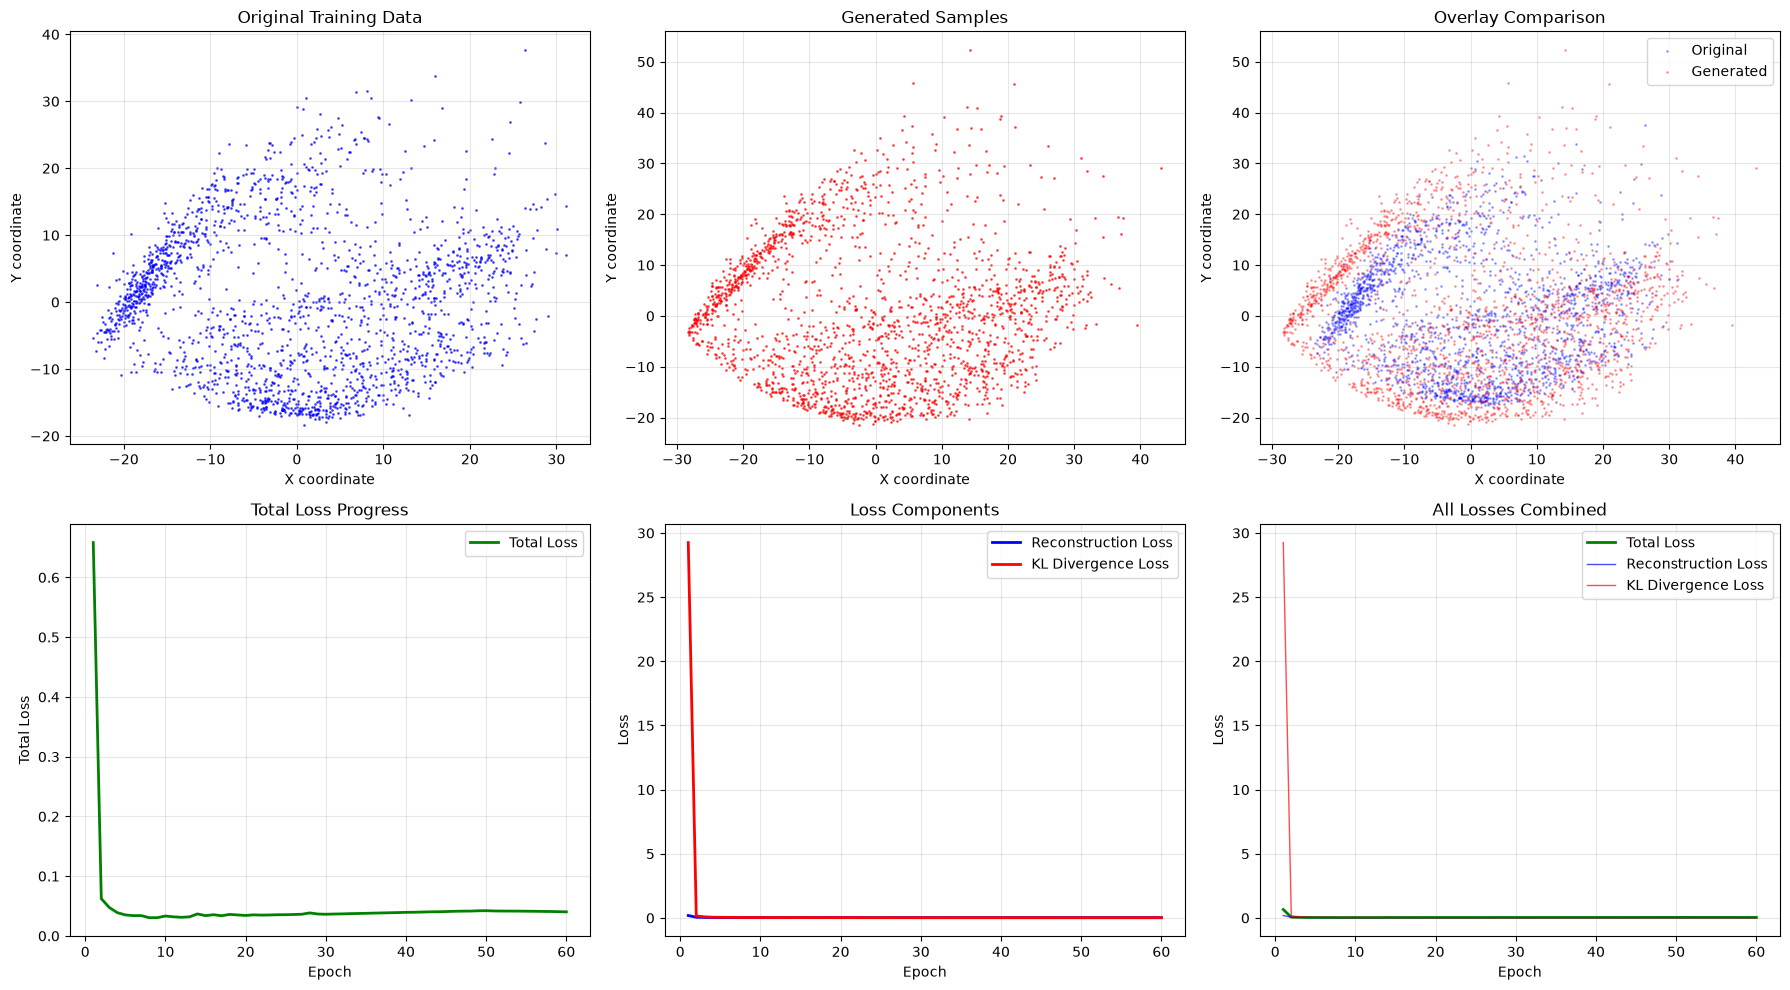

📈 Epoch 60 Summary:
   Total Loss: 0.0403
   Reconstruction Loss: 0.0269
   KL Divergence Loss: 0.0184
   Beta: 0.724
   Learning Rate: 0.000125

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/60000 (0%)]	Total Loss: 0.039169	Recon Loss: 0.026102	KL Loss: 0.018451	Beta: 0.708
Epoch: 61 [25600/60000 (42%)]	Total Loss: 0.039326	Recon Loss: 0.026510	KL Loss: 0.018097	Beta: 0.708
Epoch: 61 [51200/60000 (85%)]	Total Loss: 0.040072	Recon Loss: 0.026777	KL Loss: 0.018773	Beta: 0.708
====> Epoch: 61 Average Total Loss: 0.0399, Average Recon Loss: 0.0267, Average KL Loss: 0.0186, Beta: 0.708
📈 Epoch 61 Summary:
   Total Loss: 0.0399
   Reconstruction Loss: 0.0267
   KL Divergence Loss: 0.0186
   Beta: 0.708
   Learning Rate: 0.000125

📊 Epoch 62/200
----------------------------------------
Epoch: 62 [0/60000 (0%)]	Total Loss: 0.038873	Recon Loss: 0.026145	KL Loss: 0.018404	Beta: 0.692
Epoch: 62 [25600/60000 (42%)]	Total Loss: 0.040835	Recon Loss: 0.027841	KL Loss: 0.018789

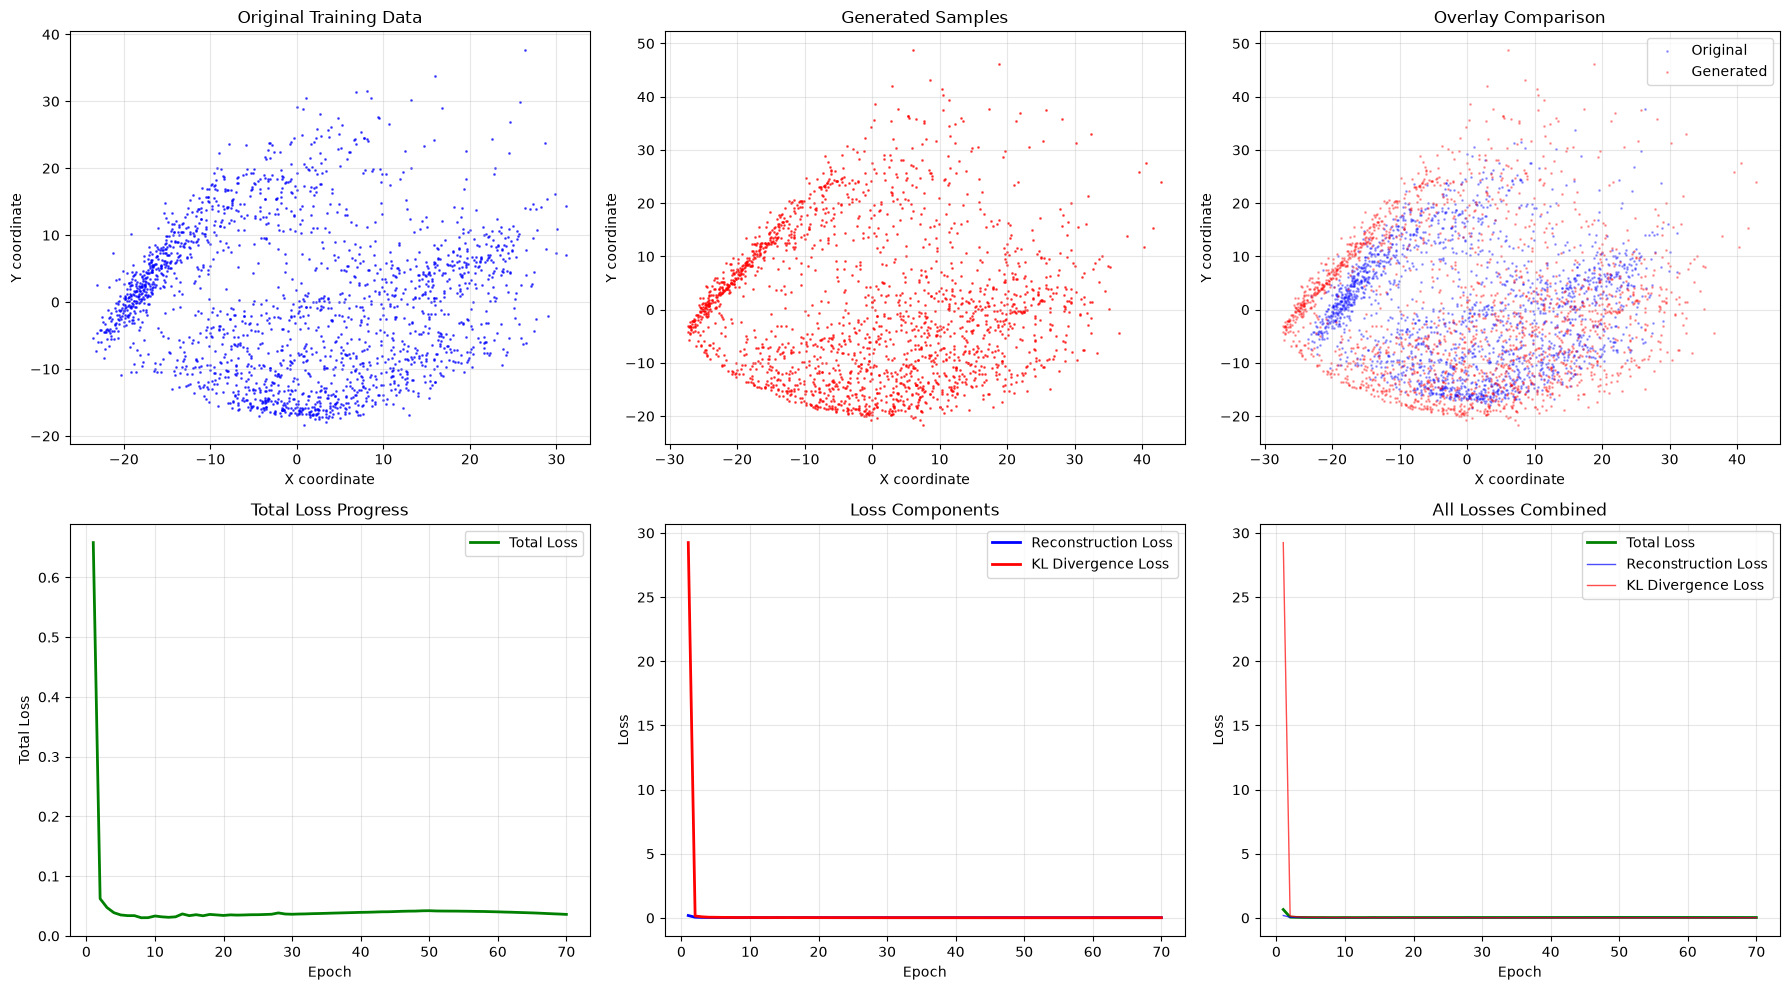

📈 Epoch 70 Summary:
   Total Loss: 0.0360
   Reconstruction Loss: 0.0249
   KL Divergence Loss: 0.0212
   Beta: 0.524
   Learning Rate: 0.000125

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/60000 (0%)]	Total Loss: 0.035895	Recon Loss: 0.025046	KL Loss: 0.021722	Beta: 0.499
Epoch: 71 [25600/60000 (42%)]	Total Loss: 0.036182	Recon Loss: 0.025134	KL Loss: 0.022118	Beta: 0.499
Epoch: 71 [51200/60000 (85%)]	Total Loss: 0.035663	Recon Loss: 0.024699	KL Loss: 0.021952	Beta: 0.499
====> Epoch: 71 Average Total Loss: 0.0355, Average Recon Loss: 0.0246, Average KL Loss: 0.0217, Beta: 0.499
📈 Epoch 71 Summary:
   Total Loss: 0.0355
   Reconstruction Loss: 0.0246
   KL Divergence Loss: 0.0217
   Beta: 0.499
   Learning Rate: 0.000063

📊 Epoch 72/200
----------------------------------------
Epoch: 72 [0/60000 (0%)]	Total Loss: 0.034312	Recon Loss: 0.023990	KL Loss: 0.021734	Beta: 0.475
Epoch: 72 [25600/60000 (42%)]	Total Loss: 0.033790	Recon Loss: 0.023240	KL Loss: 0.022213

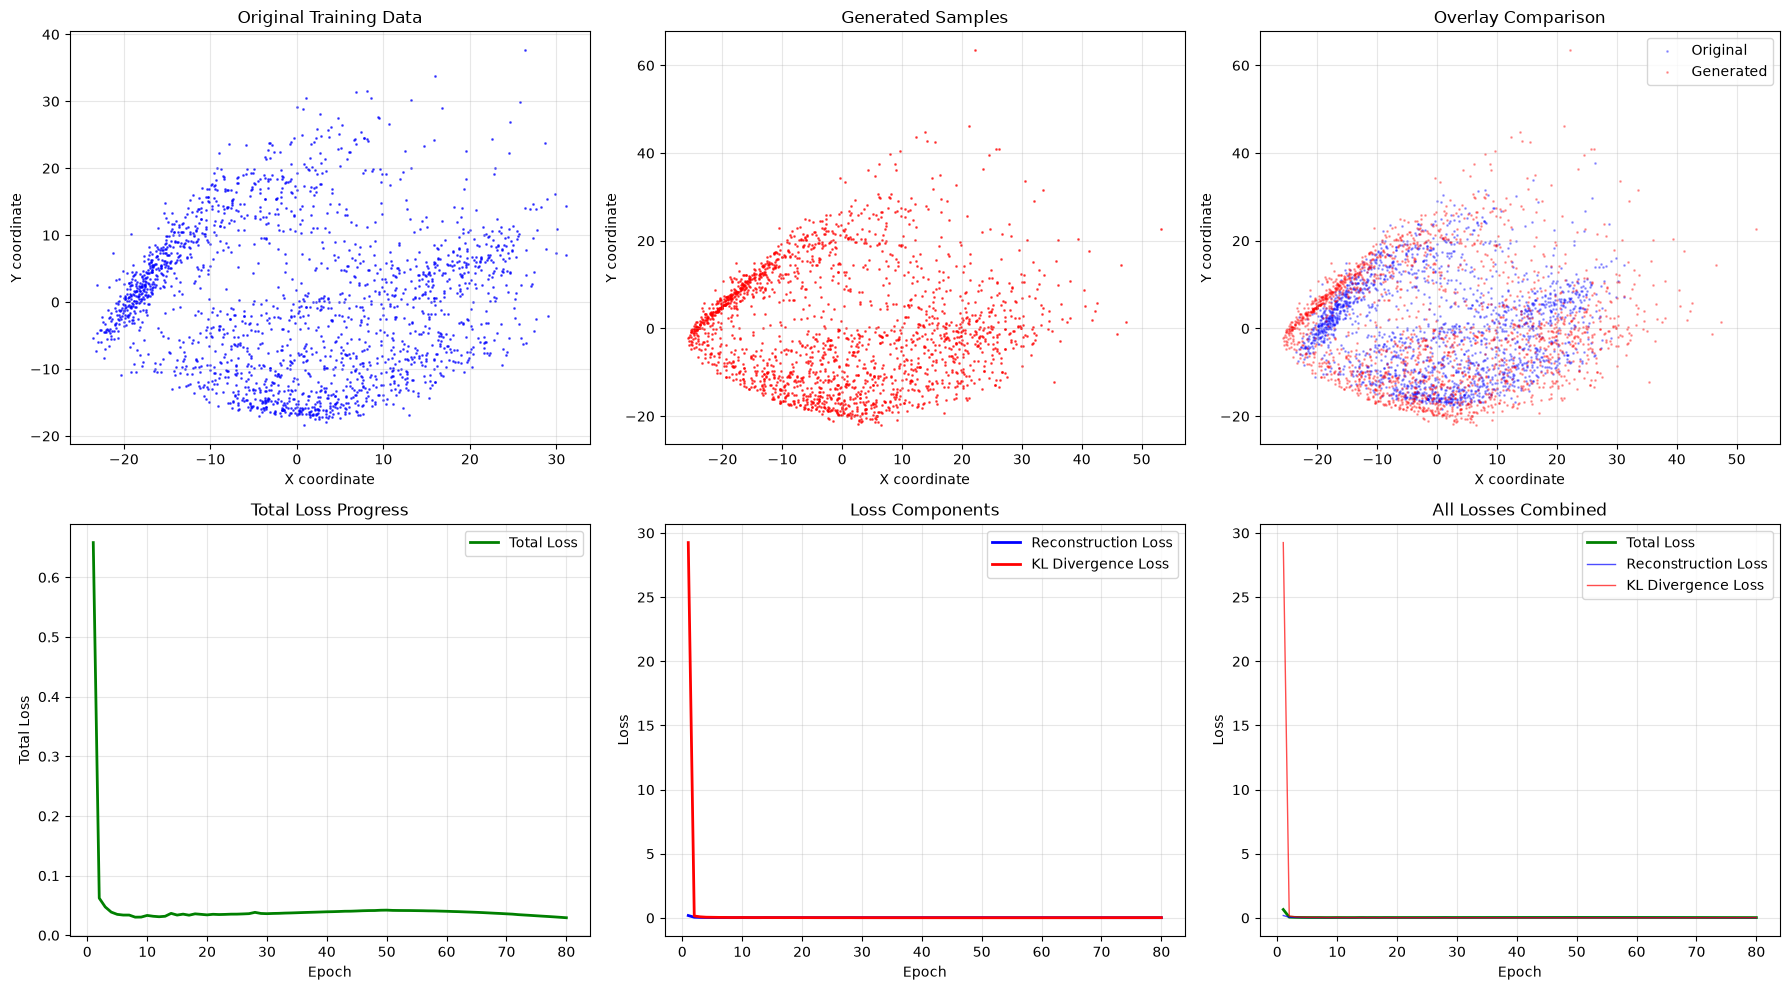

📈 Epoch 80 Summary:
   Total Loss: 0.0294
   Reconstruction Loss: 0.0220
   KL Divergence Loss: 0.0269
   Beta: 0.276
   Learning Rate: 0.000063

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/60000 (0%)]	Total Loss: 0.028869	Recon Loss: 0.022044	KL Loss: 0.027002	Beta: 0.253
Epoch: 81 [25600/60000 (42%)]	Total Loss: 0.029320	Recon Loss: 0.022347	KL Loss: 0.027590	Beta: 0.253
Epoch: 81 [51200/60000 (85%)]	Total Loss: 0.028200	Recon Loss: 0.021198	KL Loss: 0.027706	Beta: 0.253
====> Epoch: 81 Average Total Loss: 0.0287, Average Recon Loss: 0.0217, Average KL Loss: 0.0277, Beta: 0.253
📈 Epoch 81 Summary:
   Total Loss: 0.0287
   Reconstruction Loss: 0.0217
   KL Divergence Loss: 0.0277
   Beta: 0.253
   Learning Rate: 0.000063

📊 Epoch 82/200
----------------------------------------
Epoch: 82 [0/60000 (0%)]	Total Loss: 0.027804	Recon Loss: 0.021342	KL Loss: 0.028131	Beta: 0.230
Epoch: 82 [25600/60000 (42%)]	Total Loss: 0.028748	Recon Loss: 0.022163	KL Loss: 0.028669

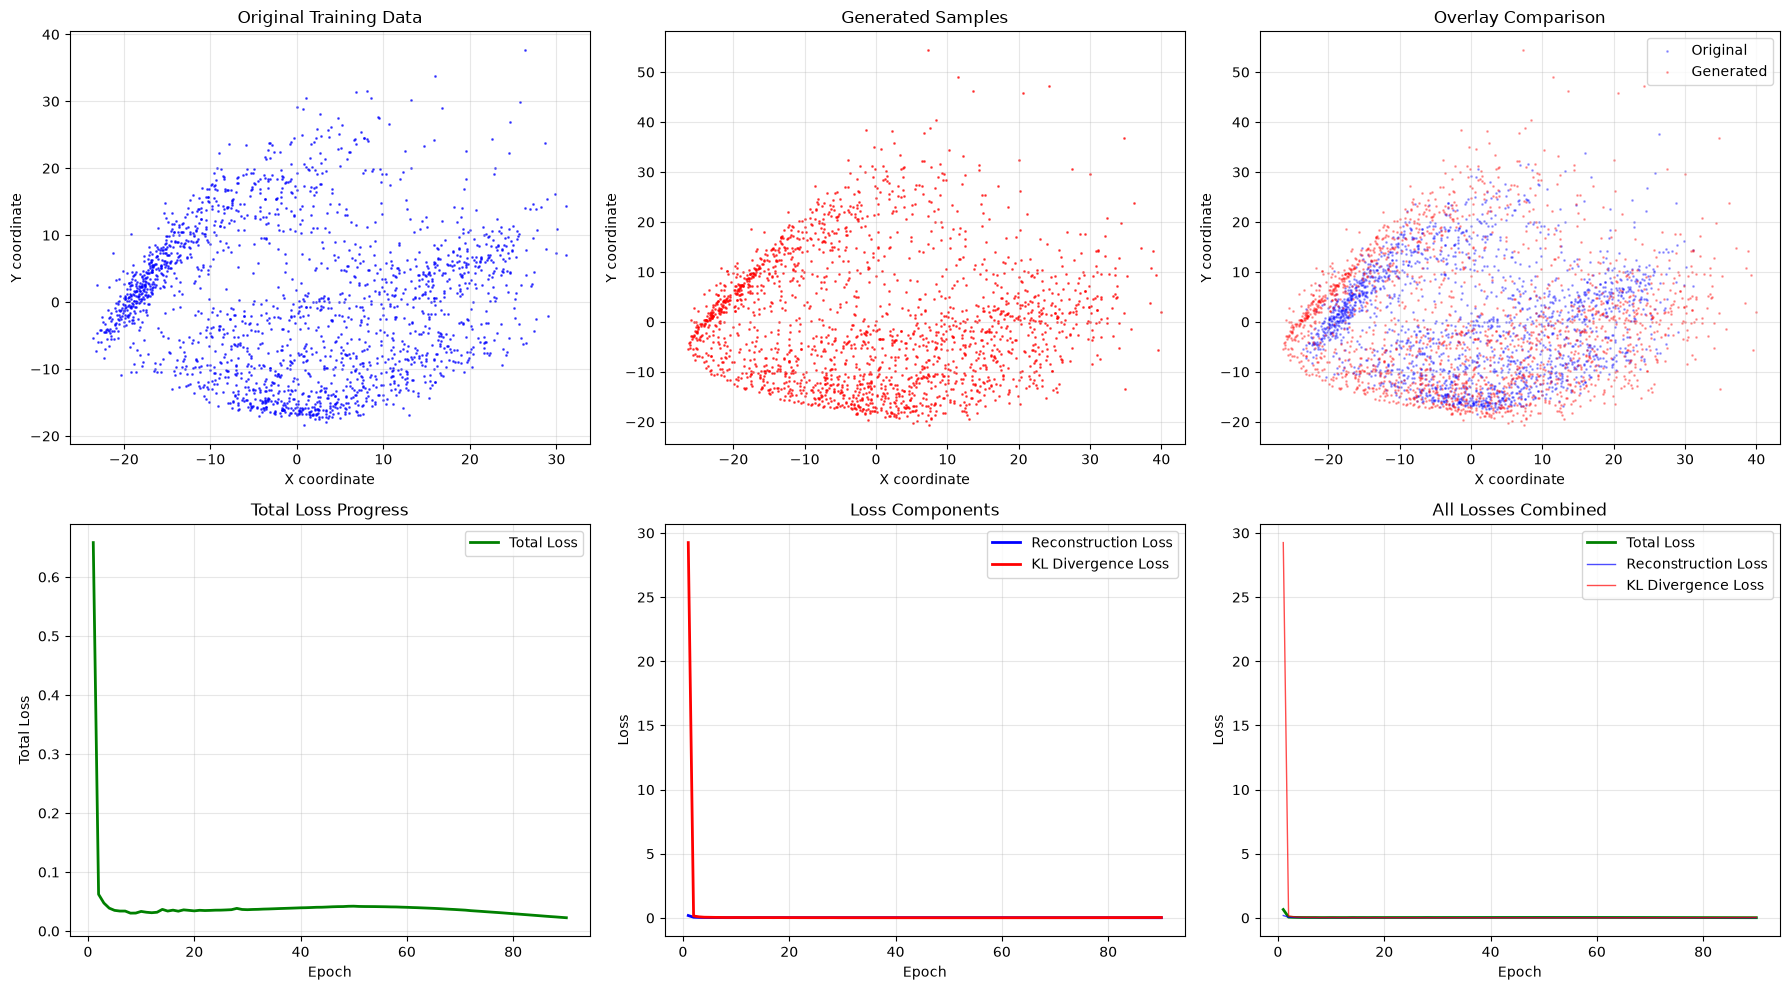

📈 Epoch 90 Summary:
   Total Loss: 0.0226
   Reconstruction Loss: 0.0197
   KL Divergence Loss: 0.0382
   Beta: 0.076
   Learning Rate: 0.000063

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/60000 (0%)]	Total Loss: 0.021440	Recon Loss: 0.019056	KL Loss: 0.038288	Beta: 0.062
Epoch: 91 [25600/60000 (42%)]	Total Loss: 0.022616	Recon Loss: 0.020130	KL Loss: 0.039936	Beta: 0.062
Epoch: 91 [51200/60000 (85%)]	Total Loss: 0.021592	Recon Loss: 0.019101	KL Loss: 0.040004	Beta: 0.062
====> Epoch: 91 Average Total Loss: 0.0220, Average Recon Loss: 0.0195, Average KL Loss: 0.0400, Beta: 0.062
📈 Epoch 91 Summary:
   Total Loss: 0.0220
   Reconstruction Loss: 0.0195
   KL Divergence Loss: 0.0400
   Beta: 0.062
   Learning Rate: 0.000063

📊 Epoch 92/200
----------------------------------------
Epoch: 92 [0/60000 (0%)]	Total Loss: 0.020915	Recon Loss: 0.018941	KL Loss: 0.039896	Beta: 0.049
Epoch: 92 [25600/60000 (42%)]	Total Loss: 0.021341	Recon Loss: 0.019261	KL Loss: 0.042032

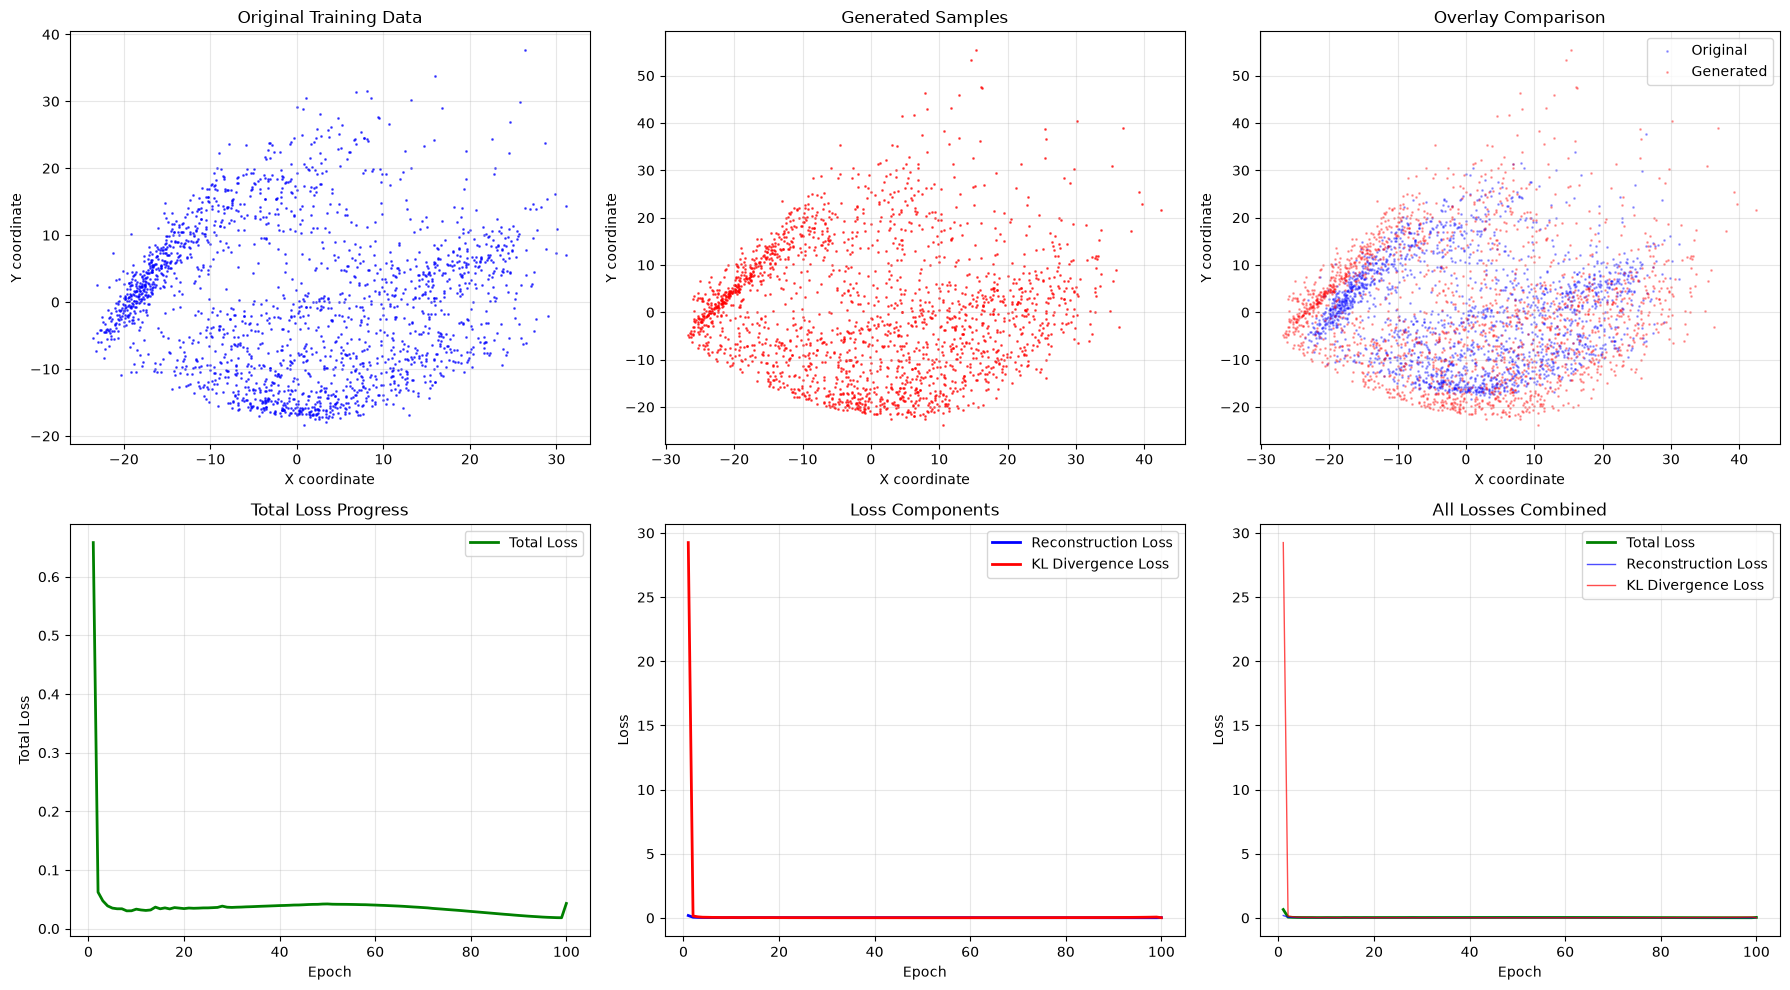

📈 Epoch 100 Summary:
   Total Loss: 0.0430
   Reconstruction Loss: 0.0260
   KL Divergence Loss: 0.0212
   Beta: 0.800
   Learning Rate: 0.000063

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/60000 (0%)]	Total Loss: 0.040801	Recon Loss: 0.025638	KL Loss: 0.018973	Beta: 0.799
Epoch: 101 [25600/60000 (42%)]	Total Loss: 0.042096	Recon Loss: 0.026768	KL Loss: 0.019179	Beta: 0.799
Epoch: 101 [51200/60000 (85%)]	Total Loss: 0.041696	Recon Loss: 0.026289	KL Loss: 0.019278	Beta: 0.799
====> Epoch: 101 Average Total Loss: 0.0412, Average Recon Loss: 0.0261, Average KL Loss: 0.0189, Beta: 0.799
📈 Epoch 101 Summary:
   Total Loss: 0.0412
   Reconstruction Loss: 0.0261
   KL Divergence Loss: 0.0189
   Beta: 0.799
   Learning Rate: 0.000063

📊 Epoch 102/200
----------------------------------------
Epoch: 102 [0/60000 (0%)]	Total Loss: 0.039998	Recon Loss: 0.025074	KL Loss: 0.018730	Beta: 0.797
Epoch: 102 [25600/60000 (42%)]	Total Loss: 0.040451	Recon Loss: 0.025606	KL Loss

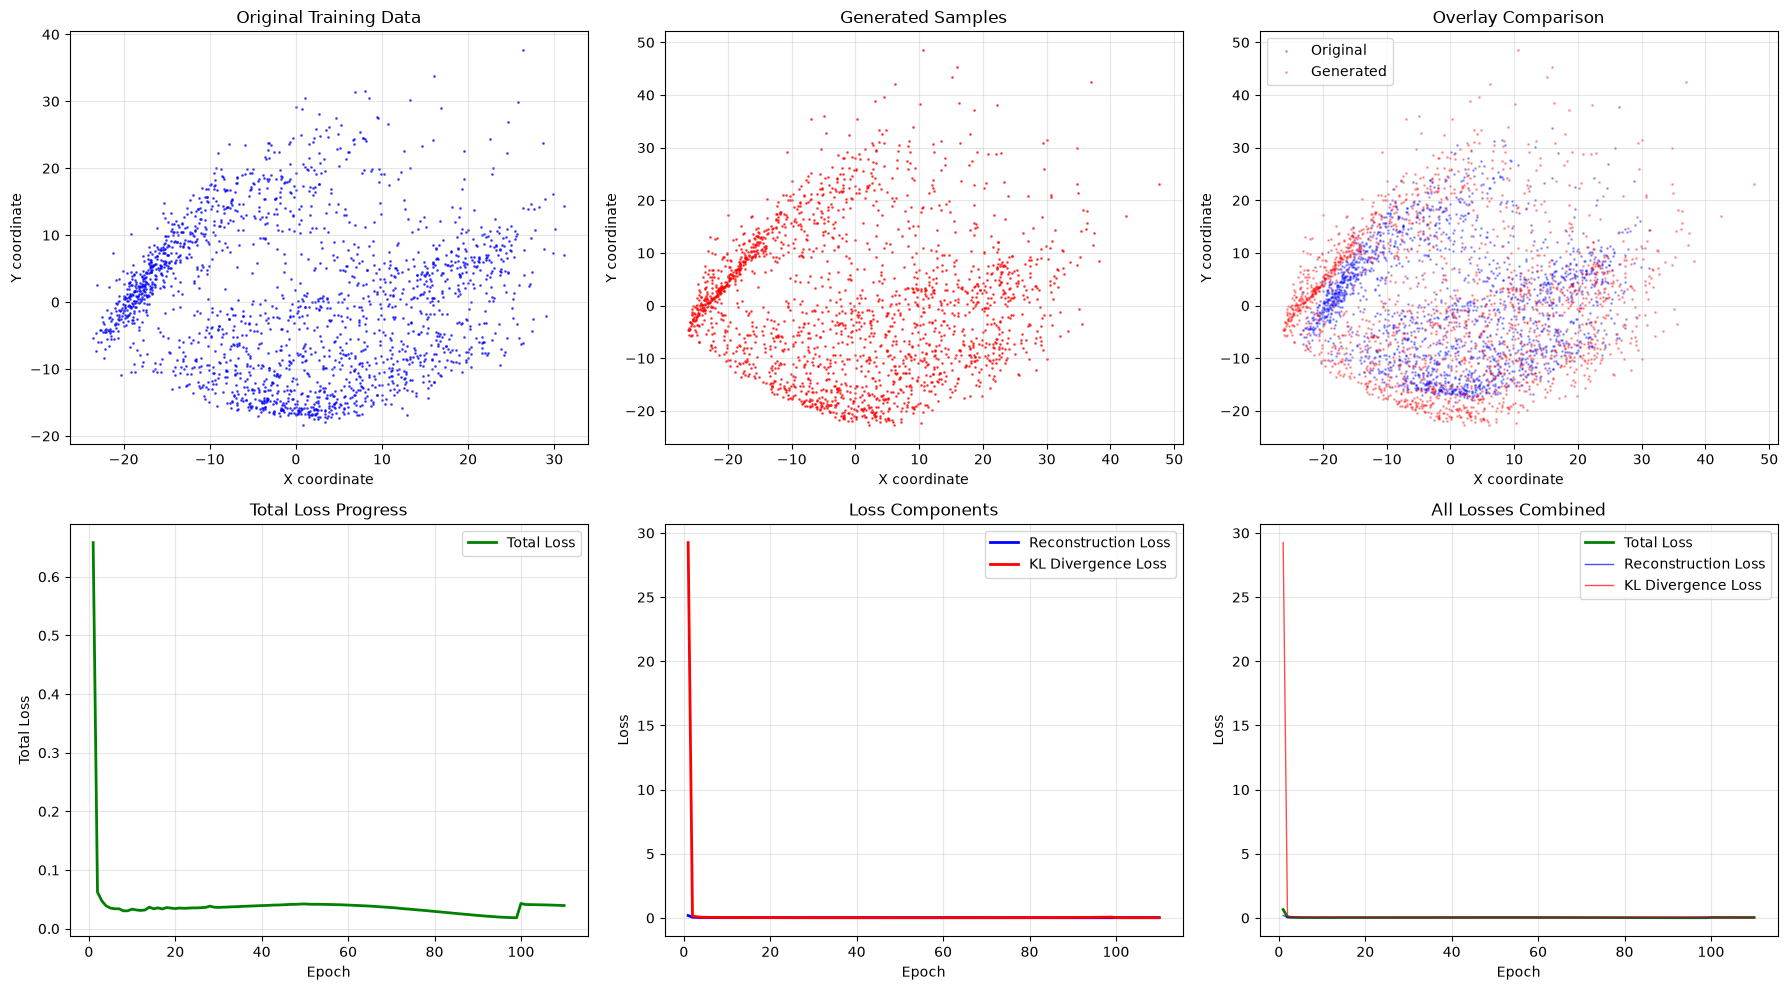

📈 Epoch 110 Summary:
   Total Loss: 0.0395
   Reconstruction Loss: 0.0255
   KL Divergence Loss: 0.0193
   Beta: 0.724
   Learning Rate: 0.000063

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/60000 (0%)]	Total Loss: 0.038765	Recon Loss: 0.025053	KL Loss: 0.019362	Beta: 0.708
Epoch: 111 [25600/60000 (42%)]	Total Loss: 0.038985	Recon Loss: 0.025100	KL Loss: 0.019606	Beta: 0.708
Epoch: 111 [51200/60000 (85%)]	Total Loss: 0.038745	Recon Loss: 0.024993	KL Loss: 0.019417	Beta: 0.708
====> Epoch: 111 Average Total Loss: 0.0391, Average Recon Loss: 0.0253, Average KL Loss: 0.0196, Beta: 0.708
📈 Epoch 111 Summary:
   Total Loss: 0.0391
   Reconstruction Loss: 0.0253
   KL Divergence Loss: 0.0196
   Beta: 0.708
   Learning Rate: 0.000063

📊 Epoch 112/200
----------------------------------------
Epoch: 112 [0/60000 (0%)]	Total Loss: 0.038506	Recon Loss: 0.024798	KL Loss: 0.019821	Beta: 0.692
Epoch: 112 [25600/60000 (42%)]	Total Loss: 0.038852	Recon Loss: 0.025185	KL Loss

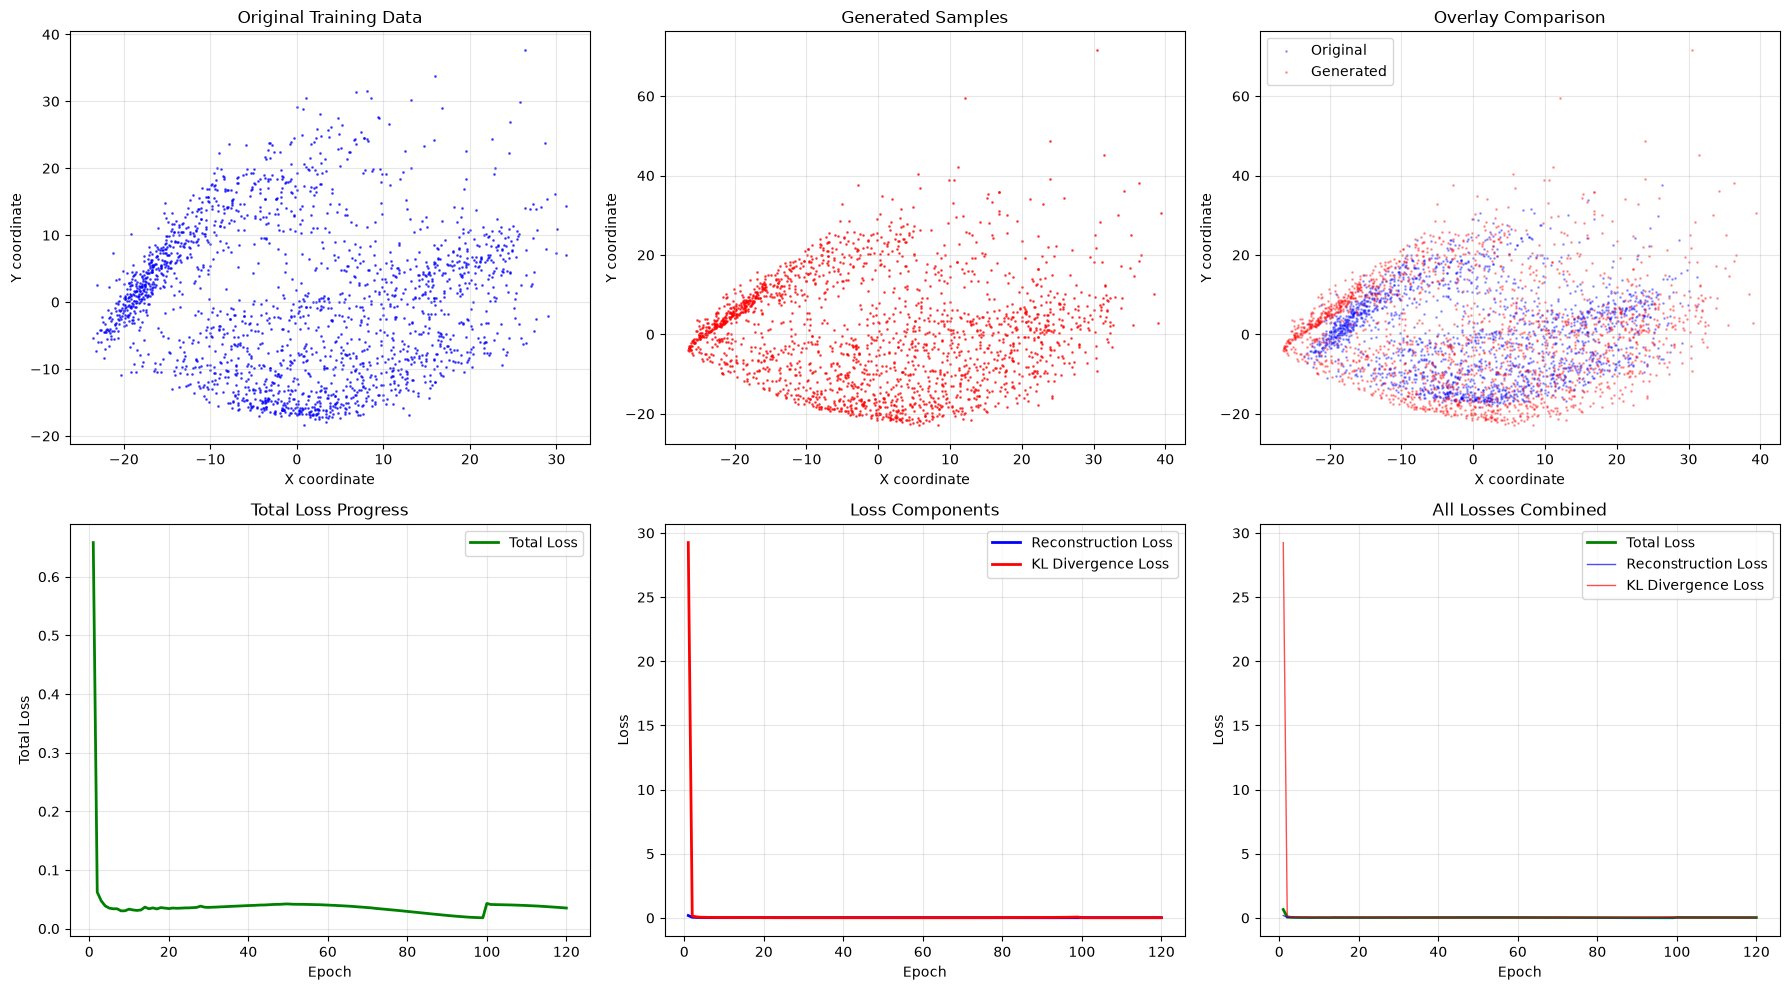

📈 Epoch 120 Summary:
   Total Loss: 0.0352
   Reconstruction Loss: 0.0236
   KL Divergence Loss: 0.0221
   Beta: 0.524
   Learning Rate: 0.000031

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/60000 (0%)]	Total Loss: 0.034393	Recon Loss: 0.023243	KL Loss: 0.022324	Beta: 0.499
Epoch: 121 [25600/60000 (42%)]	Total Loss: 0.034358	Recon Loss: 0.023063	KL Loss: 0.022613	Beta: 0.499
Epoch: 121 [51200/60000 (85%)]	Total Loss: 0.034667	Recon Loss: 0.023317	KL Loss: 0.022724	Beta: 0.499
====> Epoch: 121 Average Total Loss: 0.0344, Average Recon Loss: 0.0232, Average KL Loss: 0.0225, Beta: 0.499
📈 Epoch 121 Summary:
   Total Loss: 0.0344
   Reconstruction Loss: 0.0232
   KL Divergence Loss: 0.0225
   Beta: 0.499
   Learning Rate: 0.000031

📊 Epoch 122/200
----------------------------------------
Epoch: 122 [0/60000 (0%)]	Total Loss: 0.034651	Recon Loss: 0.023915	KL Loss: 0.022604	Beta: 0.475
Epoch: 122 [25600/60000 (42%)]	Total Loss: 0.034218	Recon Loss: 0.023302	KL Loss

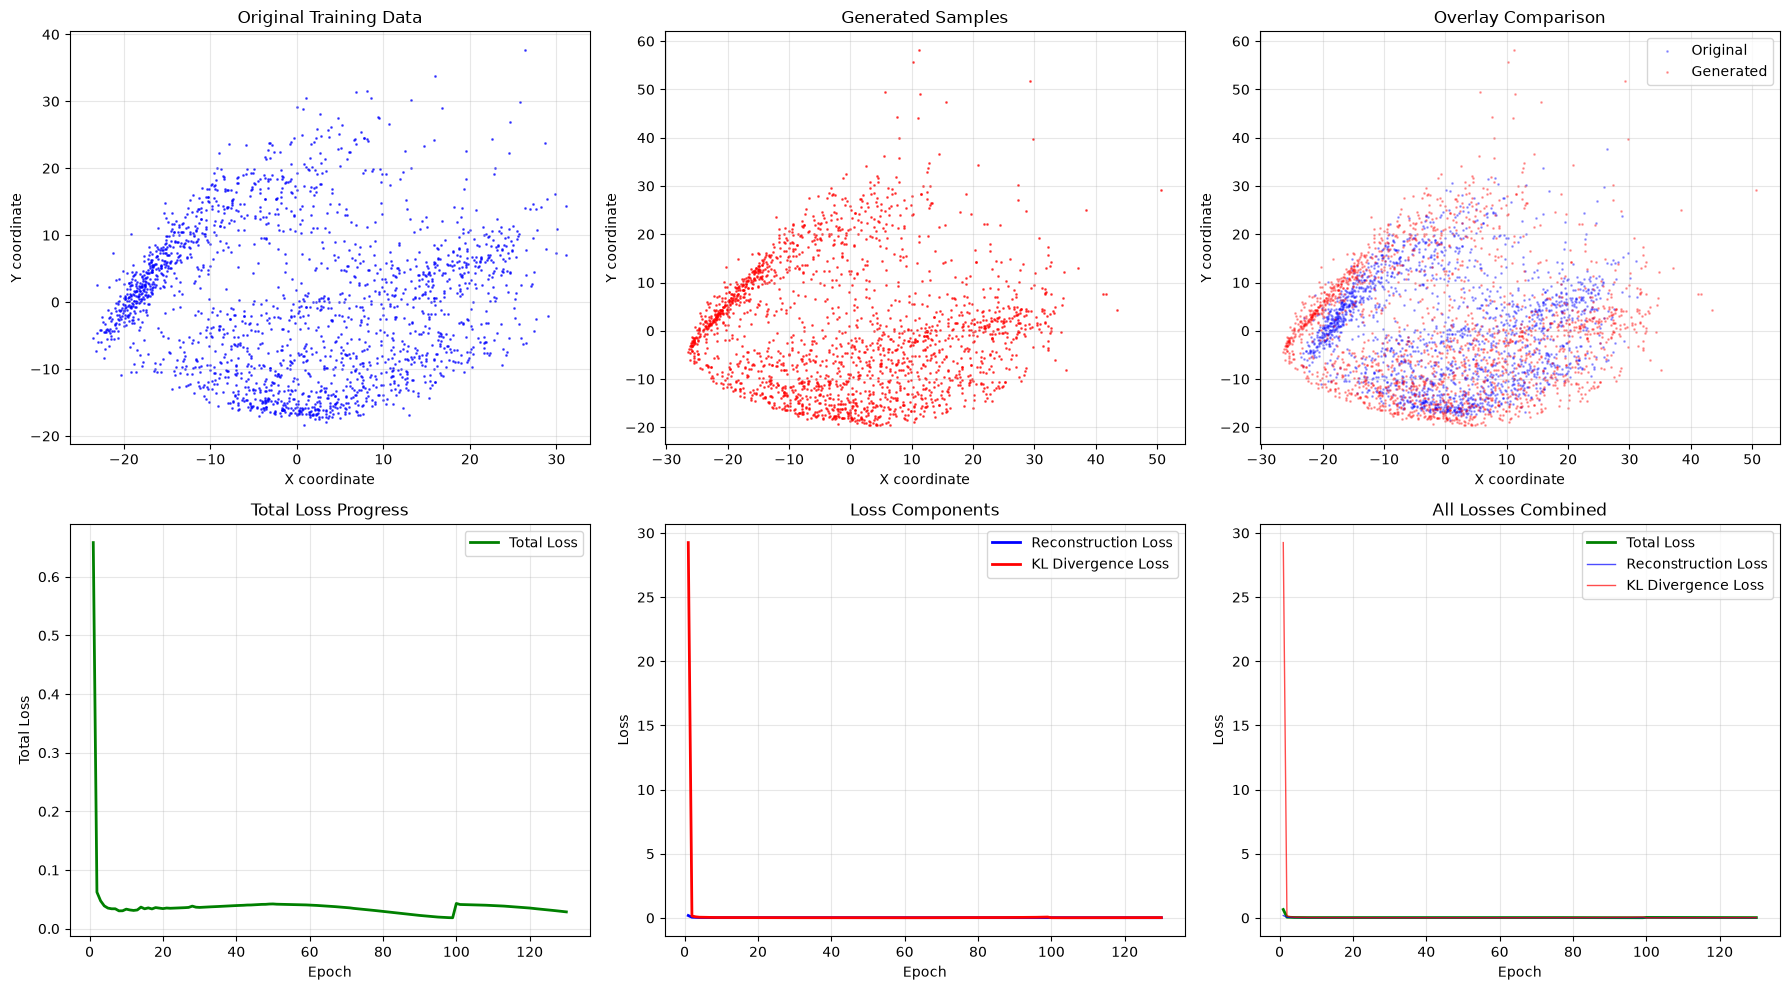

📈 Epoch 130 Summary:
   Total Loss: 0.0286
   Reconstruction Loss: 0.0210
   KL Divergence Loss: 0.0276
   Beta: 0.276
   Learning Rate: 0.000031

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/60000 (0%)]	Total Loss: 0.027631	Recon Loss: 0.020578	KL Loss: 0.027904	Beta: 0.253
Epoch: 131 [25600/60000 (42%)]	Total Loss: 0.027173	Recon Loss: 0.020007	KL Loss: 0.028350	Beta: 0.253
Epoch: 131 [51200/60000 (85%)]	Total Loss: 0.027960	Recon Loss: 0.020749	KL Loss: 0.028529	Beta: 0.253
====> Epoch: 131 Average Total Loss: 0.0280, Average Recon Loss: 0.0208, Average KL Loss: 0.0284, Beta: 0.253
📈 Epoch 131 Summary:
   Total Loss: 0.0280
   Reconstruction Loss: 0.0208
   KL Divergence Loss: 0.0284
   Beta: 0.253
   Learning Rate: 0.000031

📊 Epoch 132/200
----------------------------------------
Epoch: 132 [0/60000 (0%)]	Total Loss: 0.027298	Recon Loss: 0.020758	KL Loss: 0.028474	Beta: 0.230
Epoch: 132 [25600/60000 (42%)]	Total Loss: 0.026979	Recon Loss: 0.020296	KL Loss

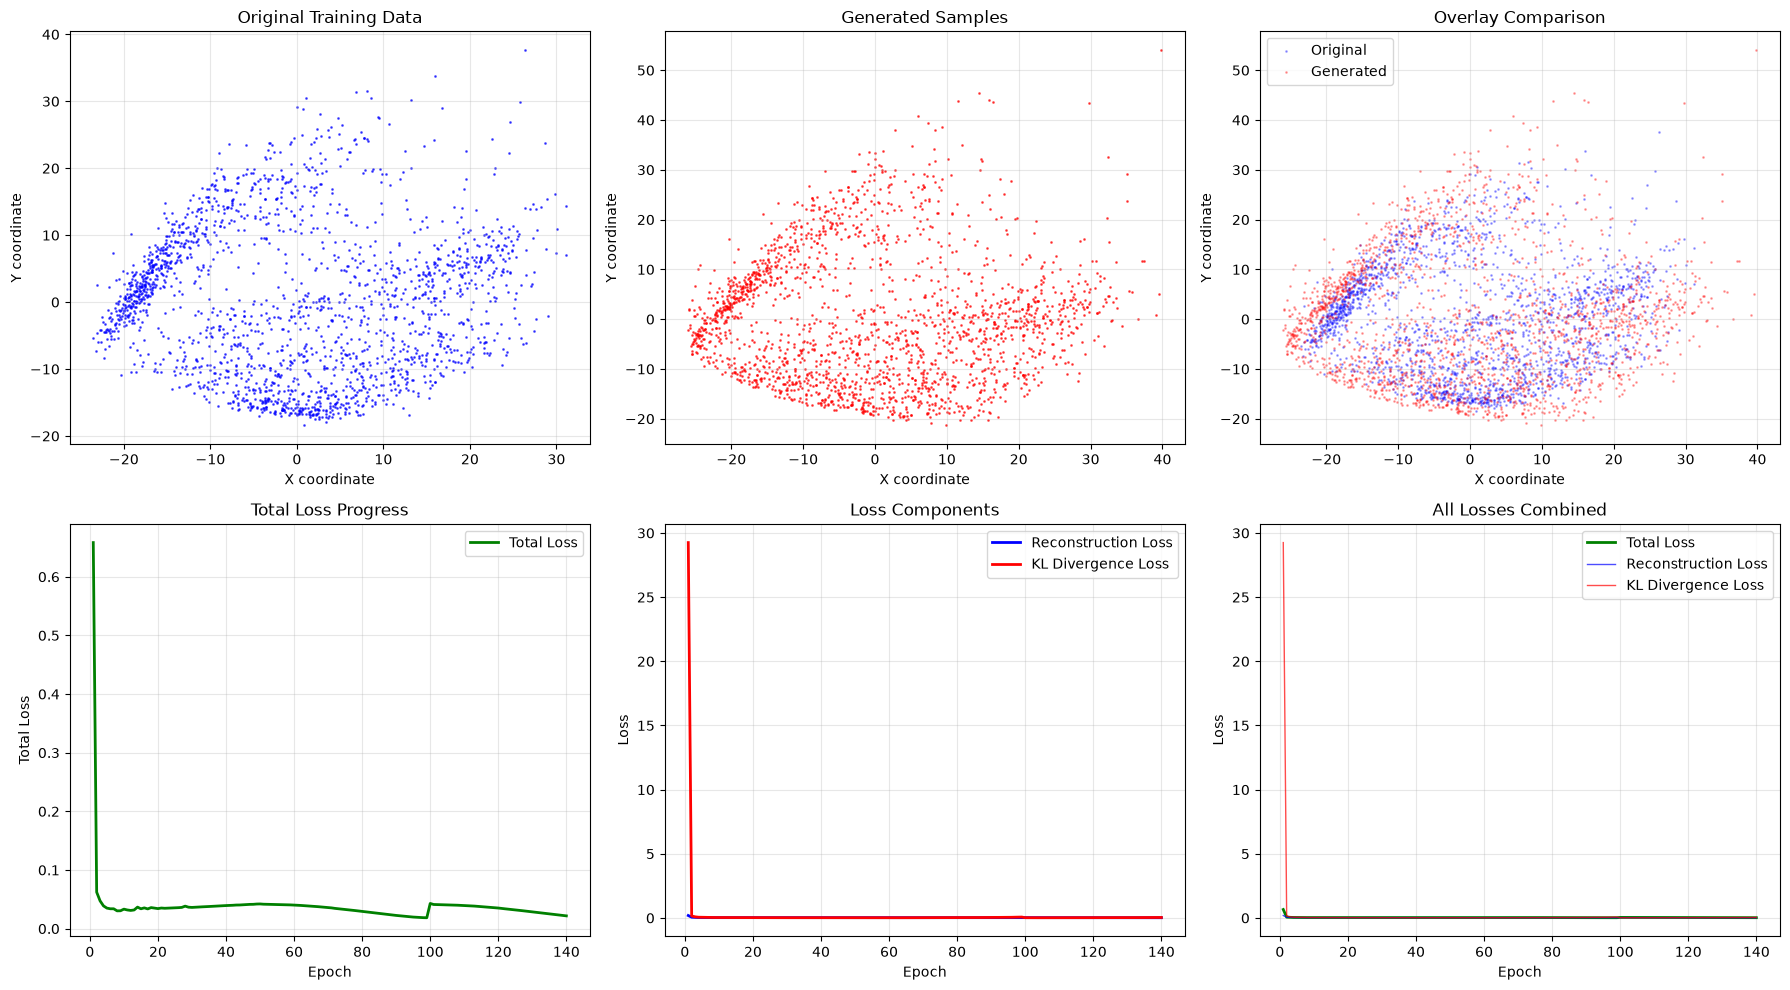

📈 Epoch 140 Summary:
   Total Loss: 0.0218
   Reconstruction Loss: 0.0189
   KL Divergence Loss: 0.0385
   Beta: 0.076
   Learning Rate: 0.000031

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/60000 (0%)]	Total Loss: 0.020908	Recon Loss: 0.018504	KL Loss: 0.038612	Beta: 0.062
Epoch: 141 [25600/60000 (42%)]	Total Loss: 0.021560	Recon Loss: 0.019060	KL Loss: 0.040150	Beta: 0.062
Epoch: 141 [51200/60000 (85%)]	Total Loss: 0.021023	Recon Loss: 0.018504	KL Loss: 0.040453	Beta: 0.062
====> Epoch: 141 Average Total Loss: 0.0212, Average Recon Loss: 0.0187, Average KL Loss: 0.0402, Beta: 0.062
📈 Epoch 141 Summary:
   Total Loss: 0.0212
   Reconstruction Loss: 0.0187
   KL Divergence Loss: 0.0402
   Beta: 0.062
   Learning Rate: 0.000016

📊 Epoch 142/200
----------------------------------------
Epoch: 142 [0/60000 (0%)]	Total Loss: 0.020796	Recon Loss: 0.018789	KL Loss: 0.040561	Beta: 0.049
Epoch: 142 [25600/60000 (42%)]	Total Loss: 0.020725	Recon Loss: 0.018630	KL Loss

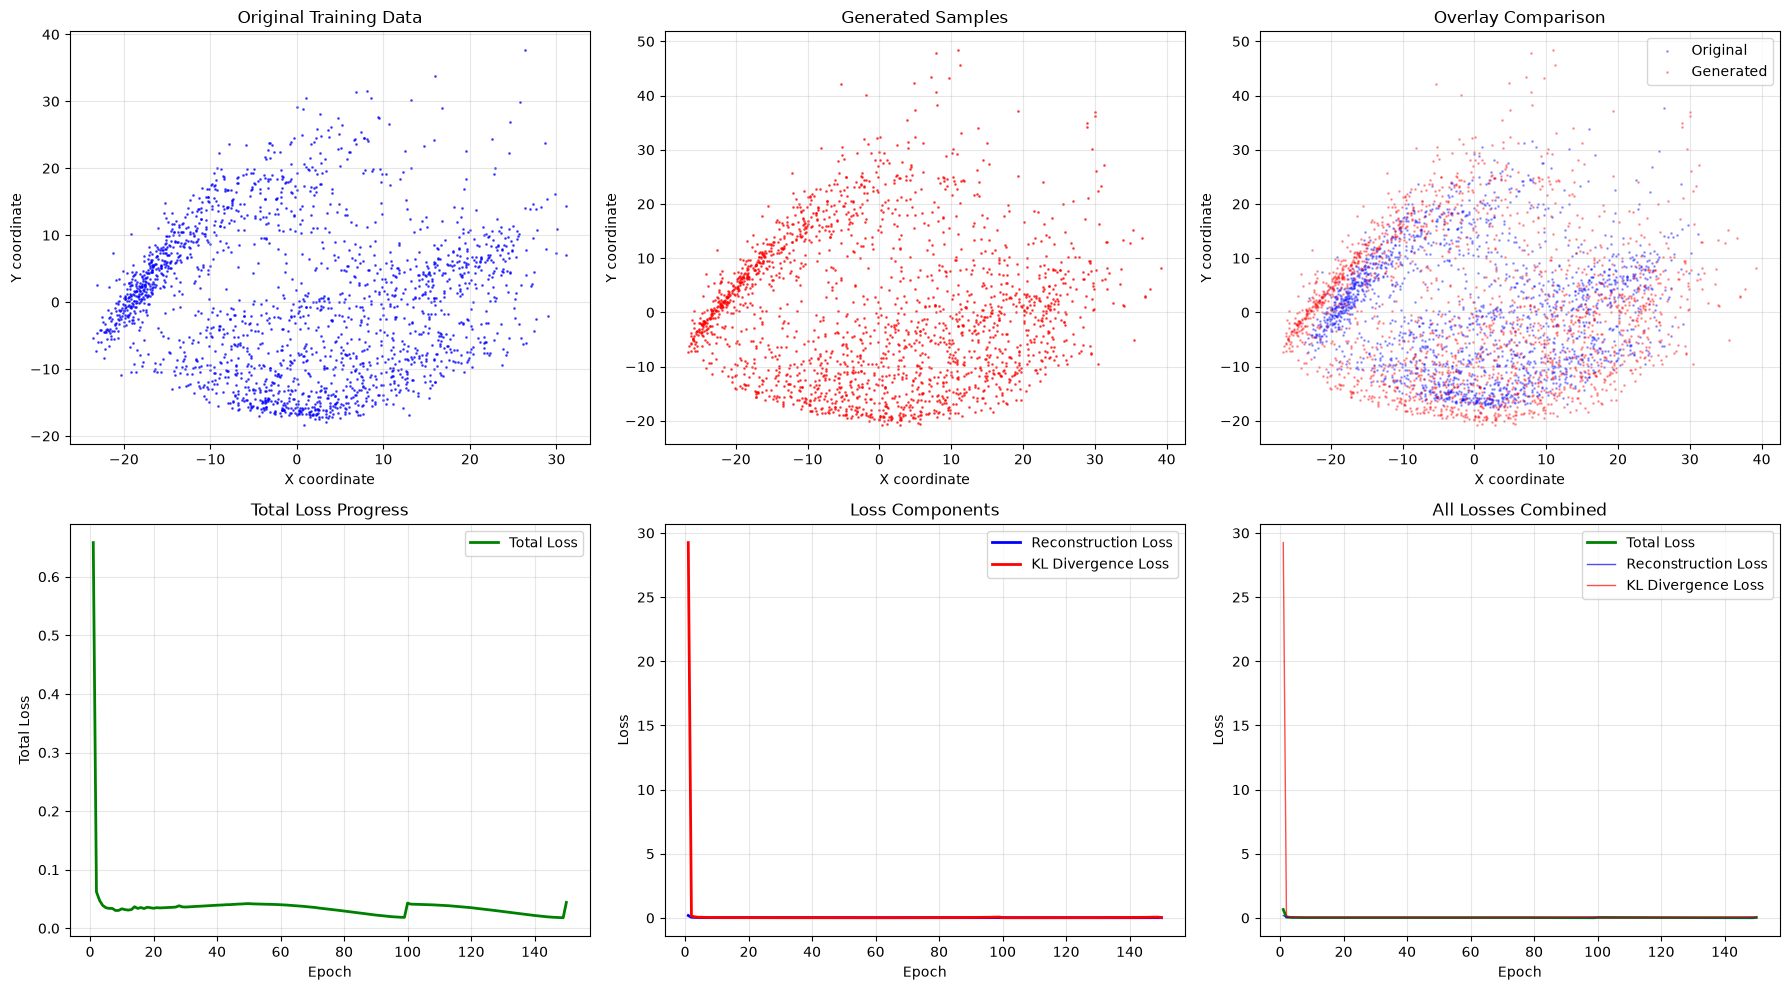

📈 Epoch 150 Summary:
   Total Loss: 0.0442
   Reconstruction Loss: 0.0232
   KL Divergence Loss: 0.0262
   Beta: 0.800
   Learning Rate: 0.000016

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/60000 (0%)]	Total Loss: 0.039564	Recon Loss: 0.023400	KL Loss: 0.020225	Beta: 0.799
Epoch: 151 [25600/60000 (42%)]	Total Loss: 0.040450	Recon Loss: 0.024592	KL Loss: 0.019842	Beta: 0.799
Epoch: 151 [51200/60000 (85%)]	Total Loss: 0.040035	Recon Loss: 0.024264	KL Loss: 0.019734	Beta: 0.799
====> Epoch: 151 Average Total Loss: 0.0407, Average Recon Loss: 0.0247, Average KL Loss: 0.0200, Beta: 0.799
📈 Epoch 151 Summary:
   Total Loss: 0.0407
   Reconstruction Loss: 0.0247
   KL Divergence Loss: 0.0200
   Beta: 0.799
   Learning Rate: 0.000016

📊 Epoch 152/200
----------------------------------------
Epoch: 152 [0/60000 (0%)]	Total Loss: 0.039645	Recon Loss: 0.024053	KL Loss: 0.019568	Beta: 0.797
Epoch: 152 [25600/60000 (42%)]	Total Loss: 0.039943	Recon Loss: 0.024178	KL Loss

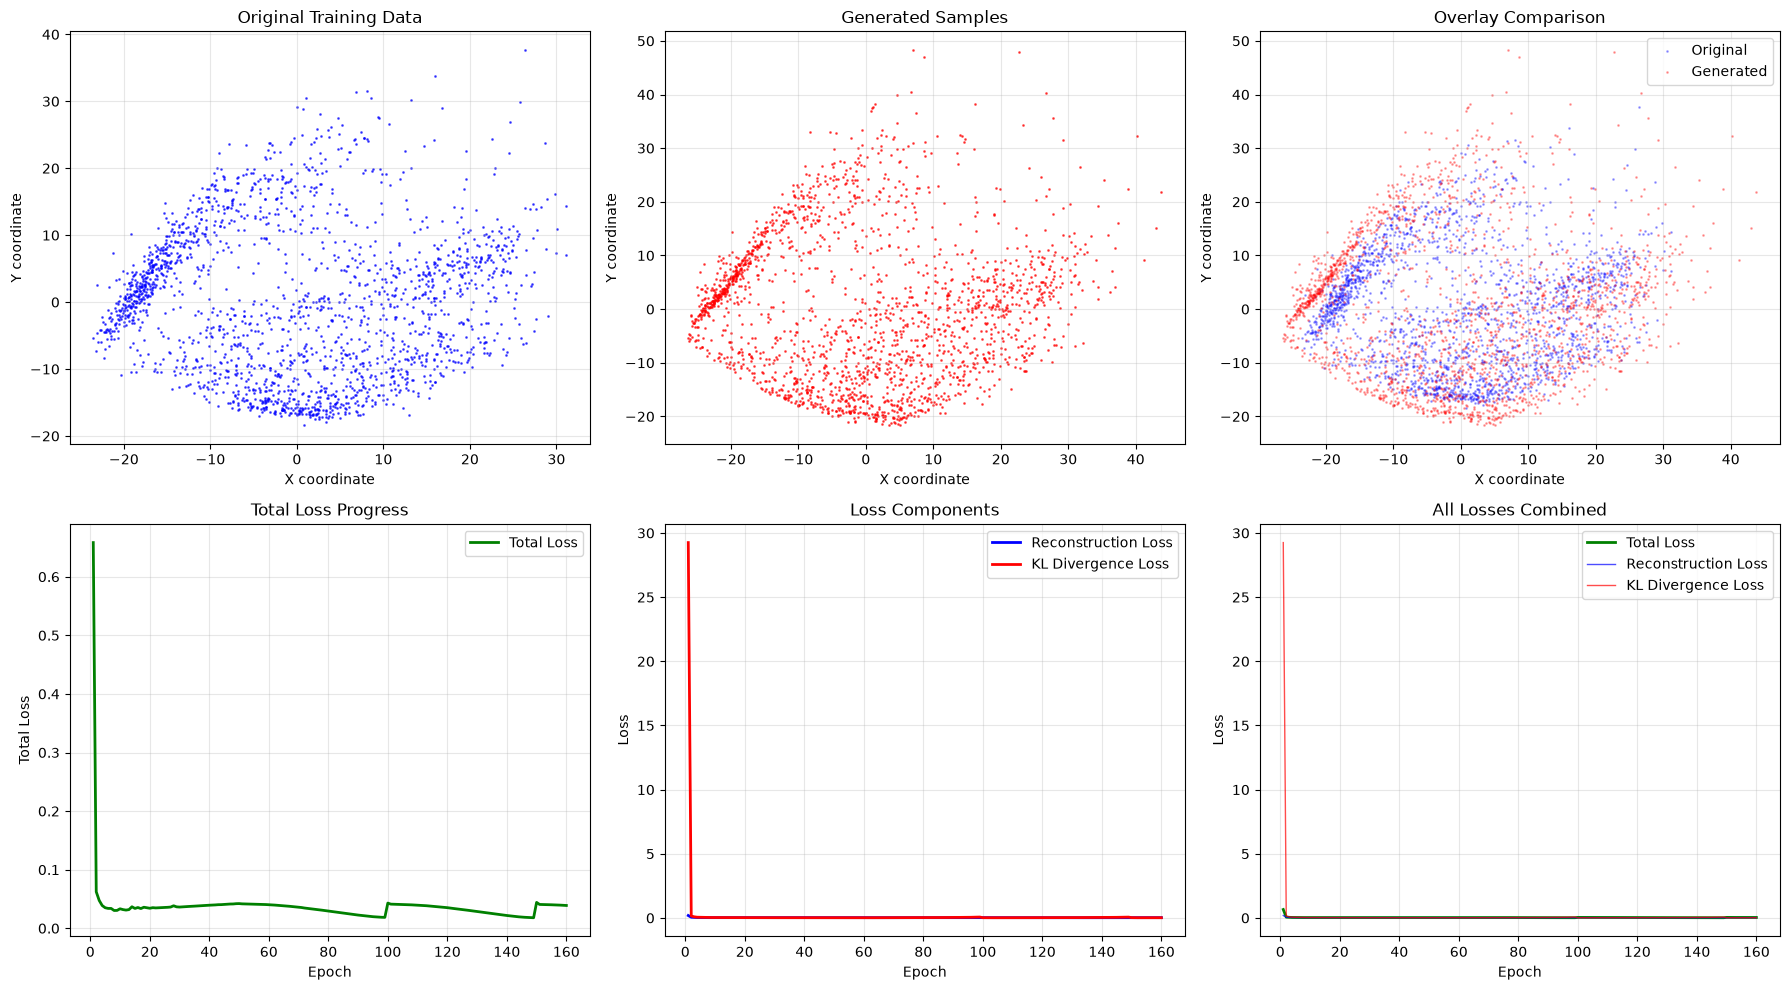

📈 Epoch 160 Summary:
   Total Loss: 0.0390
   Reconstruction Loss: 0.0244
   KL Divergence Loss: 0.0201
   Beta: 0.724
   Learning Rate: 0.000016

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/60000 (0%)]	Total Loss: 0.037655	Recon Loss: 0.023435	KL Loss: 0.020078	Beta: 0.708
Epoch: 161 [25600/60000 (42%)]	Total Loss: 0.038587	Recon Loss: 0.024280	KL Loss: 0.020202	Beta: 0.708
Epoch: 161 [51200/60000 (85%)]	Total Loss: 0.040178	Recon Loss: 0.025720	KL Loss: 0.020415	Beta: 0.708
====> Epoch: 161 Average Total Loss: 0.0386, Average Recon Loss: 0.0242, Average KL Loss: 0.0203, Beta: 0.708
📈 Epoch 161 Summary:
   Total Loss: 0.0386
   Reconstruction Loss: 0.0242
   KL Divergence Loss: 0.0203
   Beta: 0.708
   Learning Rate: 0.000016

📊 Epoch 162/200
----------------------------------------
Epoch: 162 [0/60000 (0%)]	Total Loss: 0.037978	Recon Loss: 0.024027	KL Loss: 0.020172	Beta: 0.692
Epoch: 162 [25600/60000 (42%)]	Total Loss: 0.037444	Recon Loss: 0.023393	KL Loss

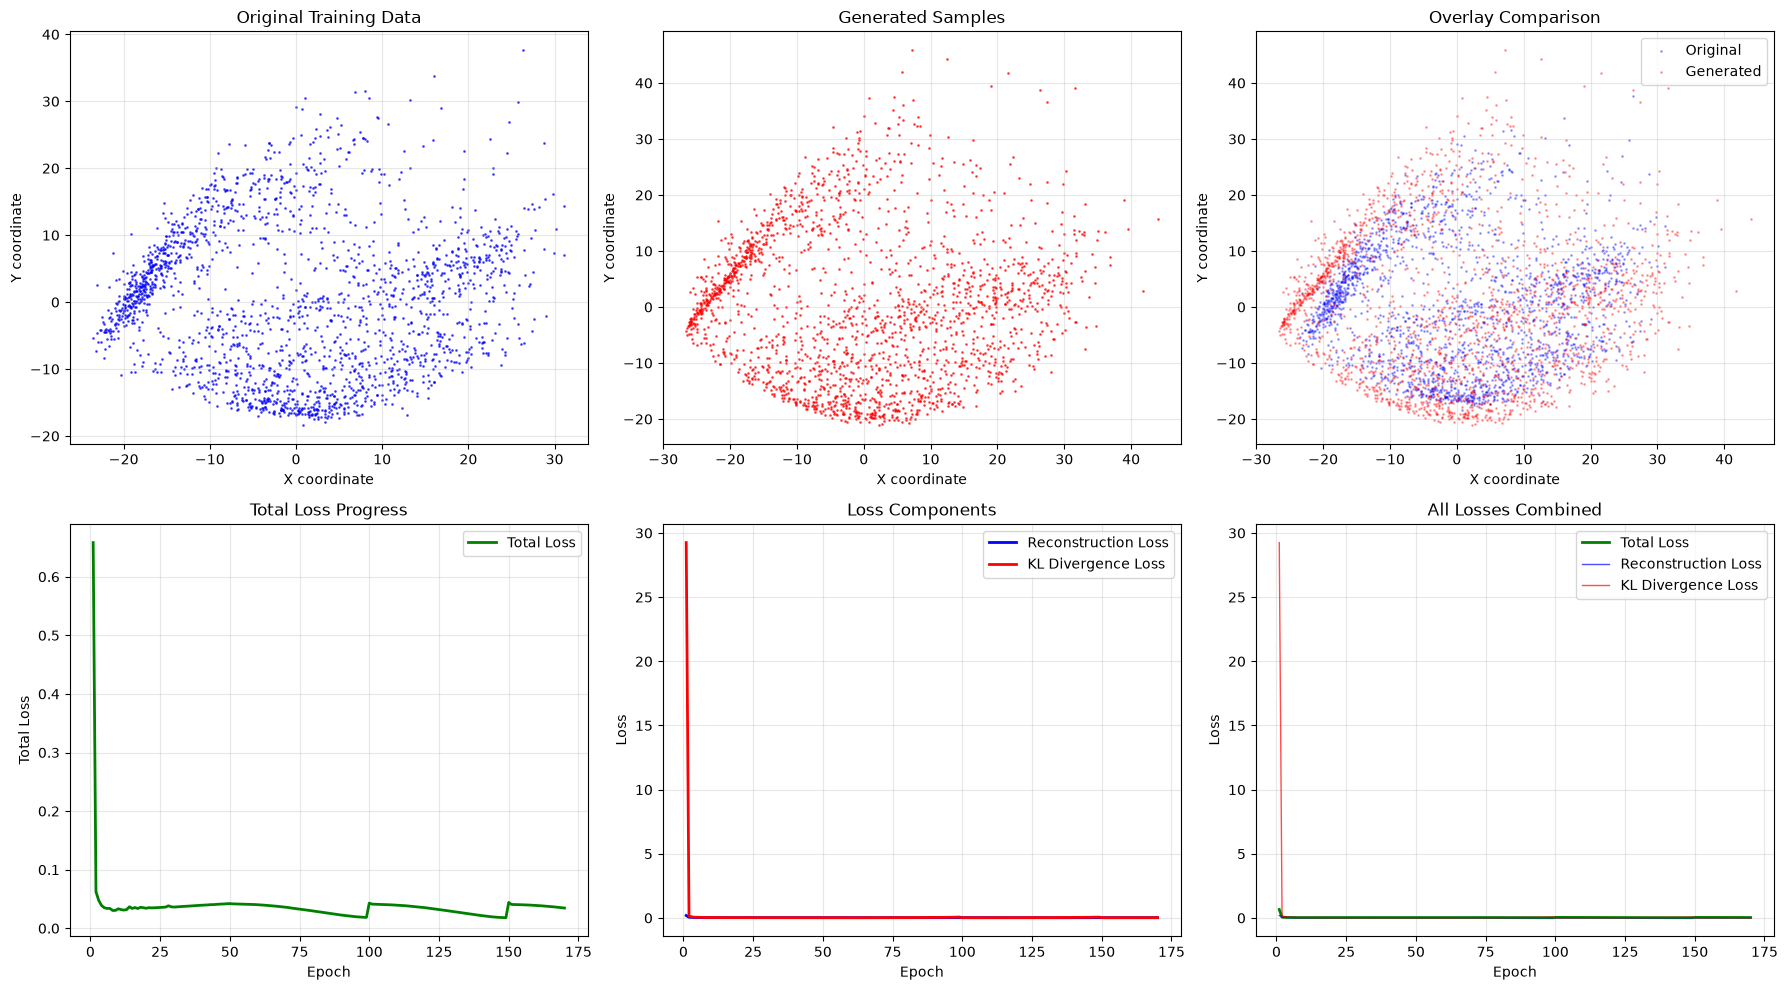

📈 Epoch 170 Summary:
   Total Loss: 0.0346
   Reconstruction Loss: 0.0226
   KL Divergence Loss: 0.0228
   Beta: 0.524
   Learning Rate: 0.000008

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/60000 (0%)]	Total Loss: 0.032990	Recon Loss: 0.021645	KL Loss: 0.022713	Beta: 0.499
Epoch: 171 [25600/60000 (42%)]	Total Loss: 0.034491	Recon Loss: 0.022898	KL Loss: 0.023210	Beta: 0.499
Epoch: 171 [51200/60000 (85%)]	Total Loss: 0.033516	Recon Loss: 0.021901	KL Loss: 0.023255	Beta: 0.499
====> Epoch: 171 Average Total Loss: 0.0340, Average Recon Loss: 0.0224, Average KL Loss: 0.0231, Beta: 0.499
📈 Epoch 171 Summary:
   Total Loss: 0.0340
   Reconstruction Loss: 0.0224
   KL Divergence Loss: 0.0231
   Beta: 0.499
   Learning Rate: 0.000008

📊 Epoch 172/200
----------------------------------------
Epoch: 172 [0/60000 (0%)]	Total Loss: 0.033382	Recon Loss: 0.022234	KL Loss: 0.023471	Beta: 0.475
Epoch: 172 [25600/60000 (42%)]	Total Loss: 0.032656	Recon Loss: 0.021476	KL Loss

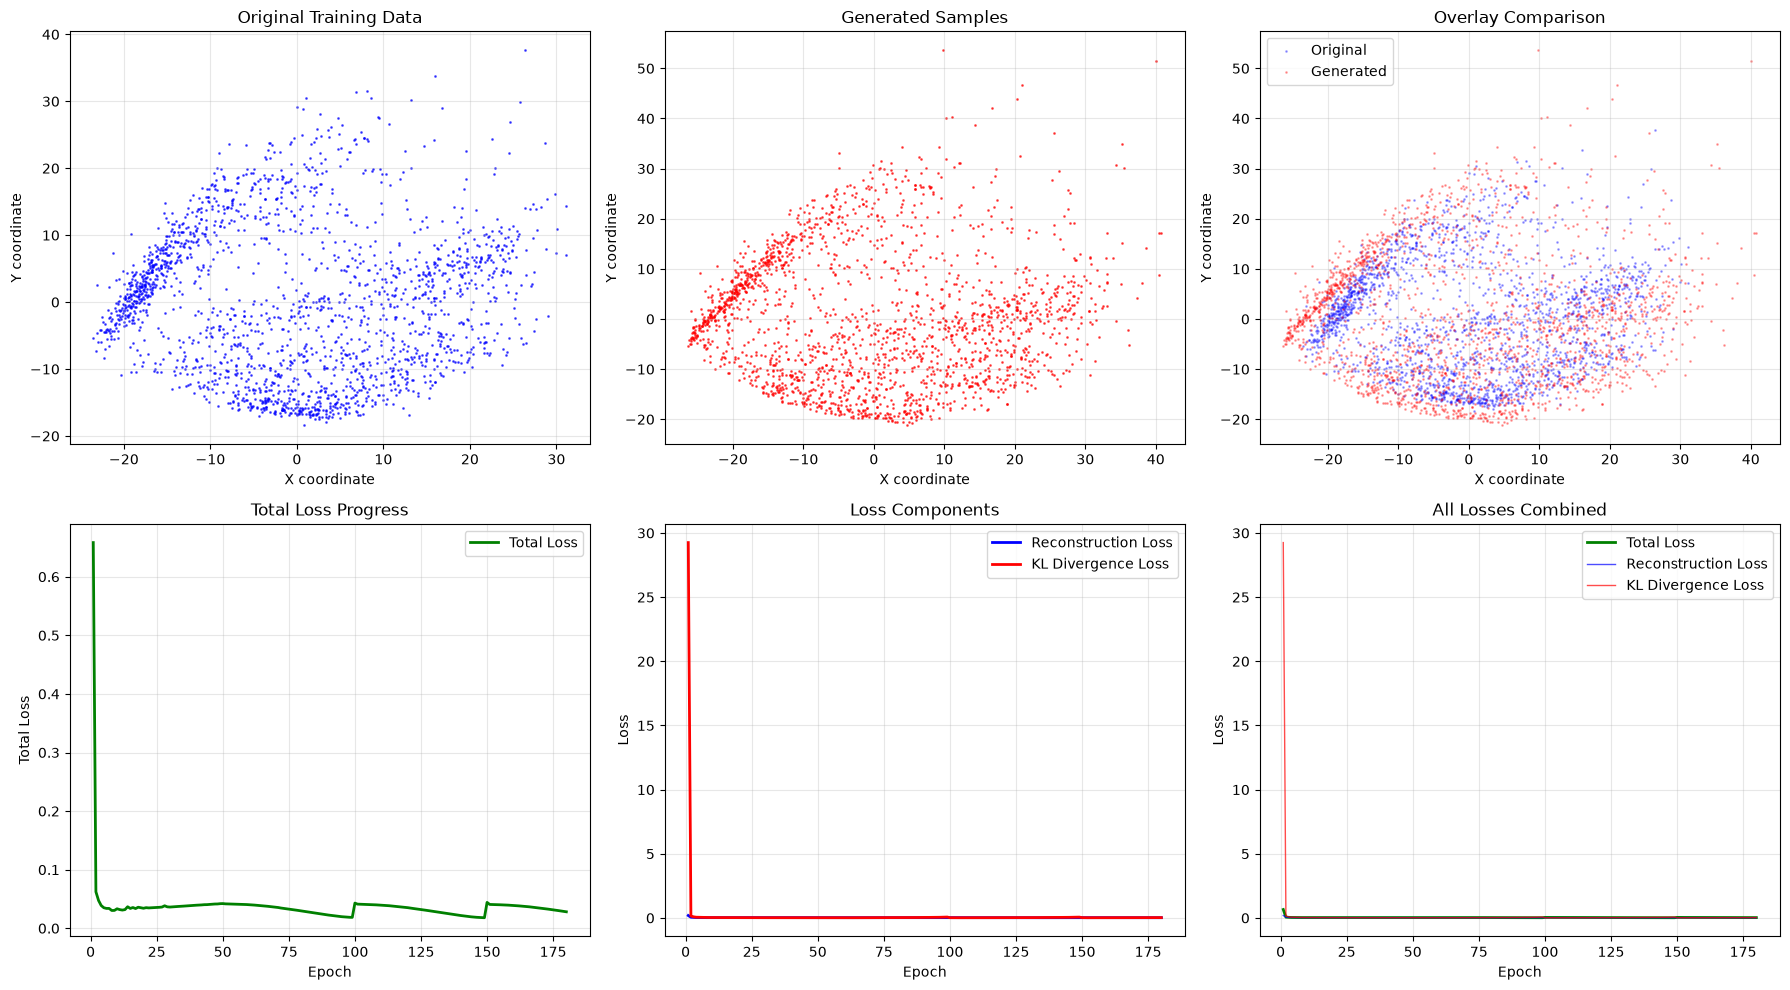

📈 Epoch 180 Summary:
   Total Loss: 0.0282
   Reconstruction Loss: 0.0204
   KL Divergence Loss: 0.0279
   Beta: 0.276
   Learning Rate: 0.000008

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/60000 (0%)]	Total Loss: 0.027548	Recon Loss: 0.020456	KL Loss: 0.028060	Beta: 0.253
Epoch: 181 [25600/60000 (42%)]	Total Loss: 0.027563	Recon Loss: 0.020305	KL Loss: 0.028717	Beta: 0.253
Epoch: 181 [51200/60000 (85%)]	Total Loss: 0.028224	Recon Loss: 0.020923	KL Loss: 0.028889	Beta: 0.253
====> Epoch: 181 Average Total Loss: 0.0275, Average Recon Loss: 0.0202, Average KL Loss: 0.0287, Beta: 0.253
📈 Epoch 181 Summary:
   Total Loss: 0.0275
   Reconstruction Loss: 0.0202
   KL Divergence Loss: 0.0287
   Beta: 0.253
   Learning Rate: 0.000008

📊 Epoch 182/200
----------------------------------------
Epoch: 182 [0/60000 (0%)]	Total Loss: 0.026627	Recon Loss: 0.020024	KL Loss: 0.028745	Beta: 0.230
Epoch: 182 [25600/60000 (42%)]	Total Loss: 0.026177	Recon Loss: 0.019383	KL Loss

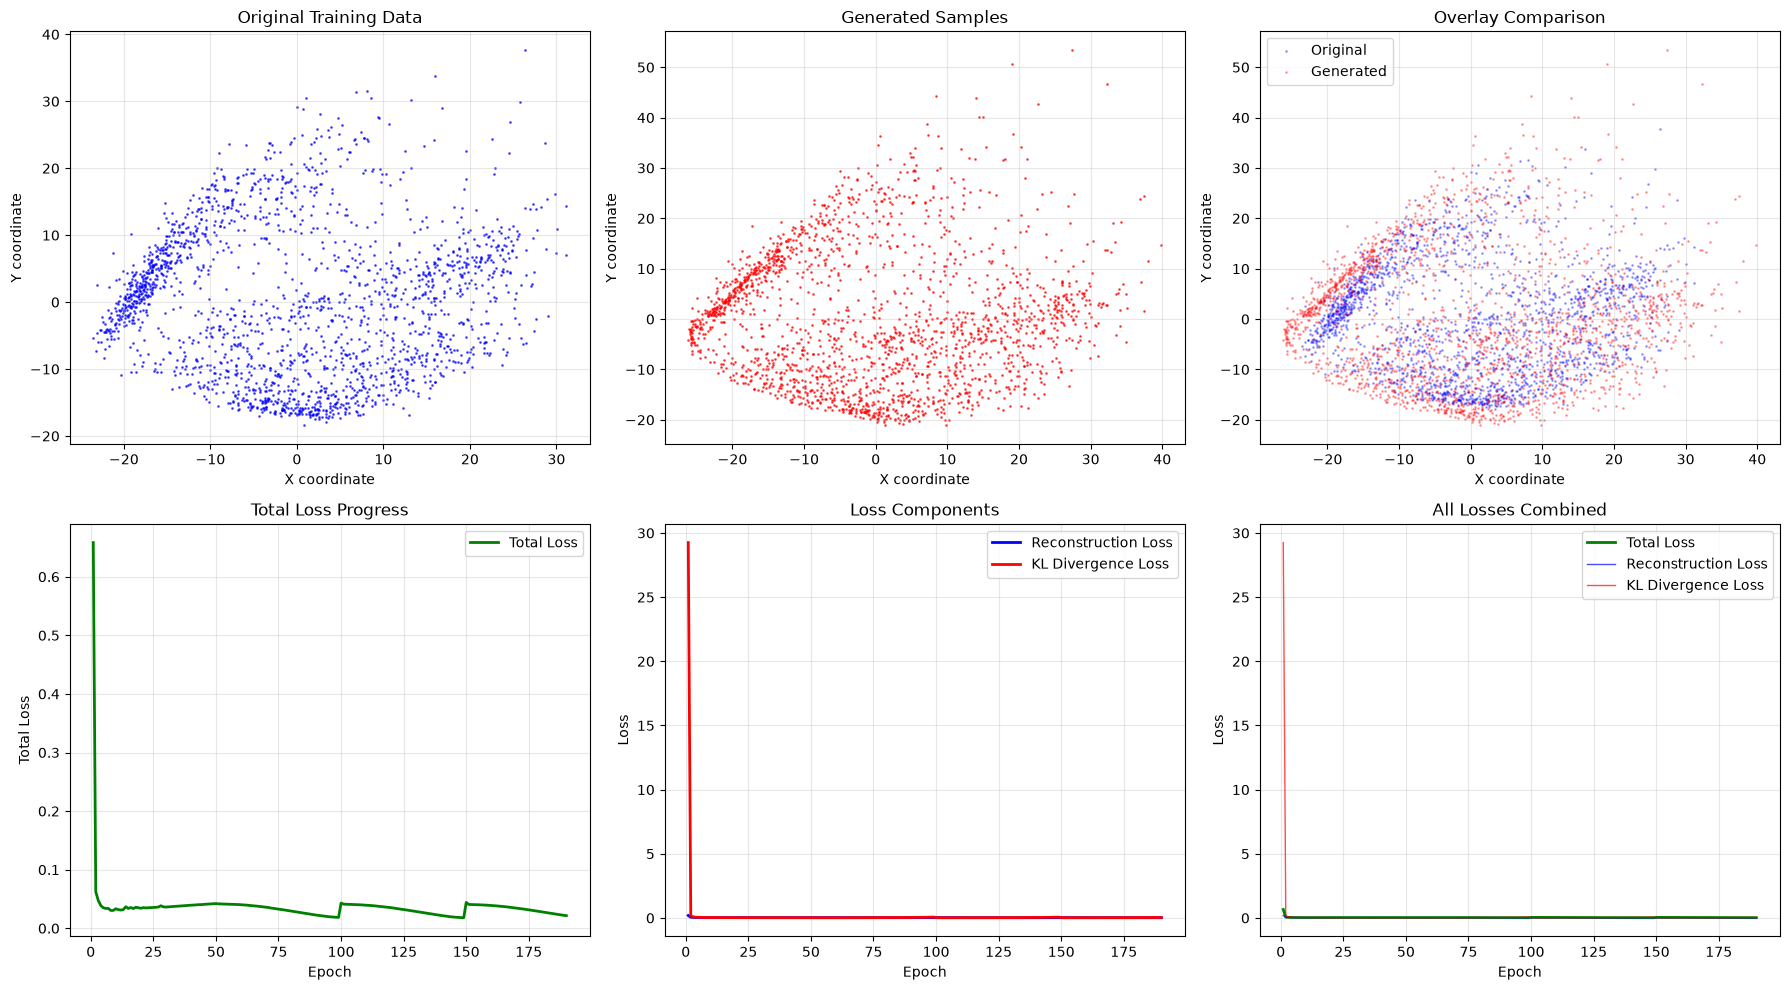

📈 Epoch 190 Summary:
   Total Loss: 0.0215
   Reconstruction Loss: 0.0186
   KL Divergence Loss: 0.0384
   Beta: 0.076
   Learning Rate: 0.000008

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/60000 (0%)]	Total Loss: 0.021175	Recon Loss: 0.018768	KL Loss: 0.038651	Beta: 0.062
Epoch: 191 [25600/60000 (42%)]	Total Loss: 0.020590	Recon Loss: 0.018090	KL Loss: 0.040151	Beta: 0.062
Epoch: 191 [51200/60000 (85%)]	Total Loss: 0.020376	Recon Loss: 0.017865	KL Loss: 0.040317	Beta: 0.062
====> Epoch: 191 Average Total Loss: 0.0210, Average Recon Loss: 0.0185, Average KL Loss: 0.0400, Beta: 0.062
📈 Epoch 191 Summary:
   Total Loss: 0.0210
   Reconstruction Loss: 0.0185
   KL Divergence Loss: 0.0400
   Beta: 0.062
   Learning Rate: 0.000004

📊 Epoch 192/200
----------------------------------------
Epoch: 192 [0/60000 (0%)]	Total Loss: 0.020341	Recon Loss: 0.018347	KL Loss: 0.040303	Beta: 0.049
Epoch: 192 [25600/60000 (42%)]	Total Loss: 0.020876	Recon Loss: 0.018810	KL Loss

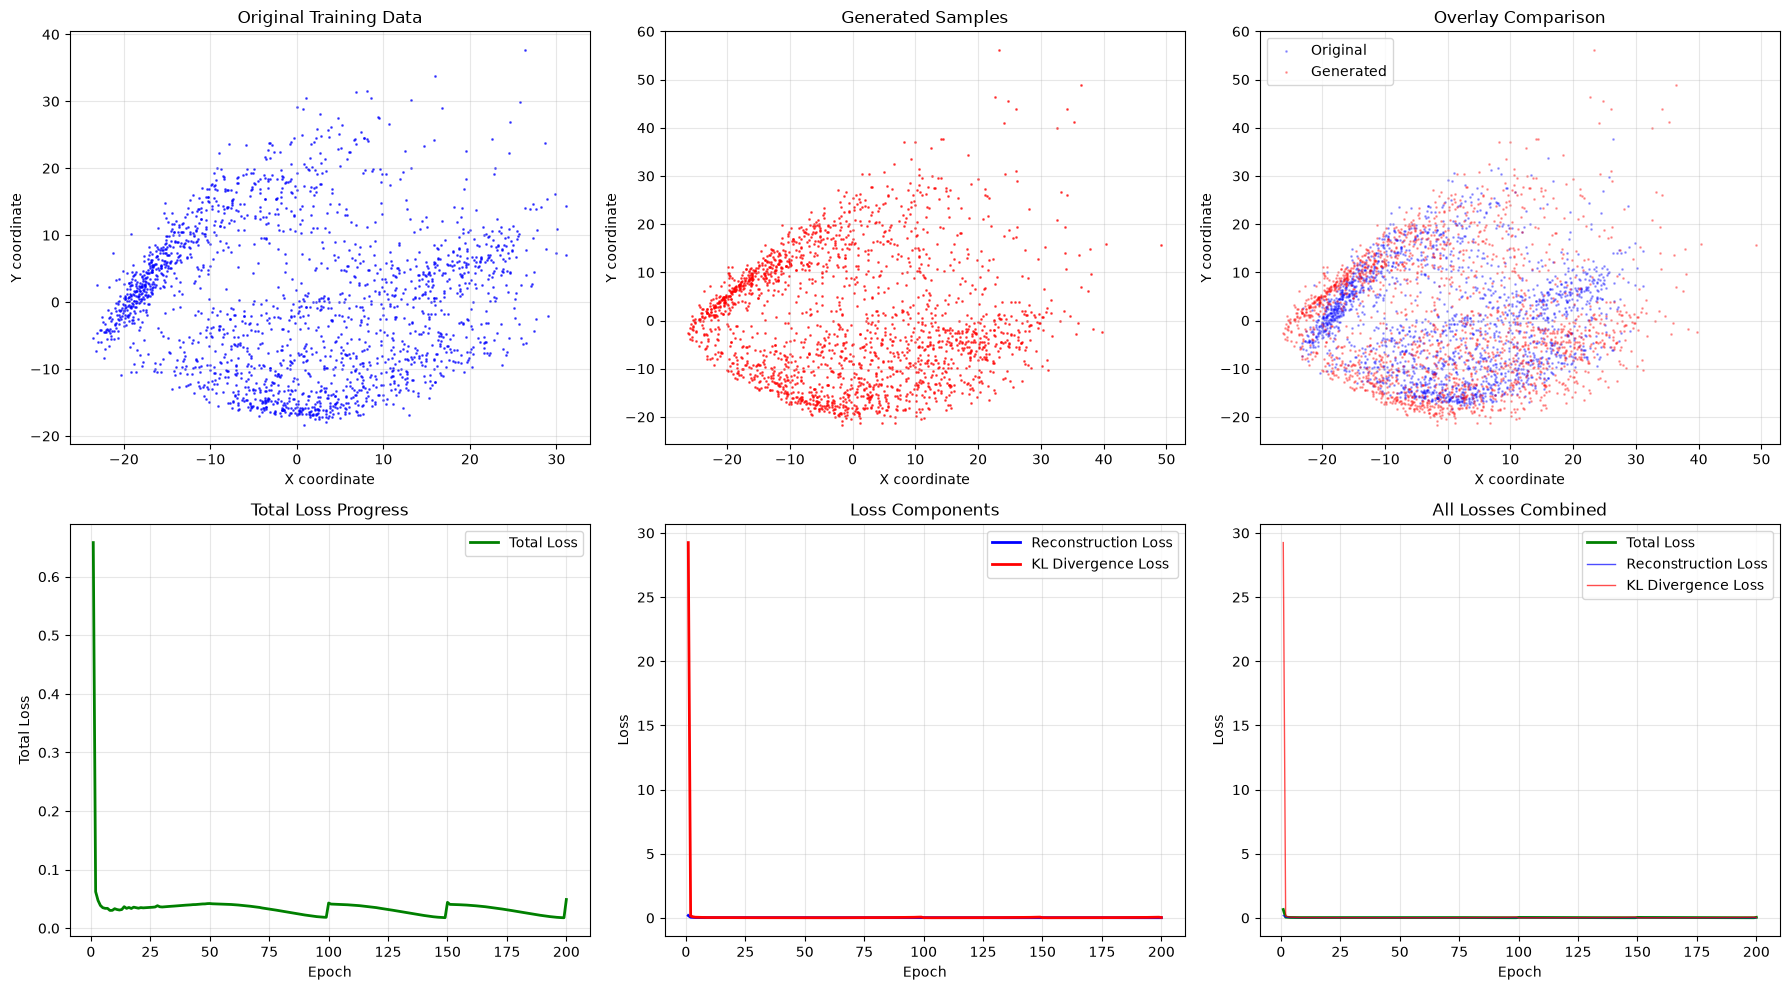

📈 Epoch 200 Summary:
   Total Loss: 0.0490
   Reconstruction Loss: 0.0197
   KL Divergence Loss: 0.0367
   Beta: 0.800
   Learning Rate: 0.000004

🎉 Training completed!
💾 Model saved as 'vae_model.pth'

🎨 Final comprehensive visualization:
💾 Saved plot: vae_results/vae_progress_epoch_200.png


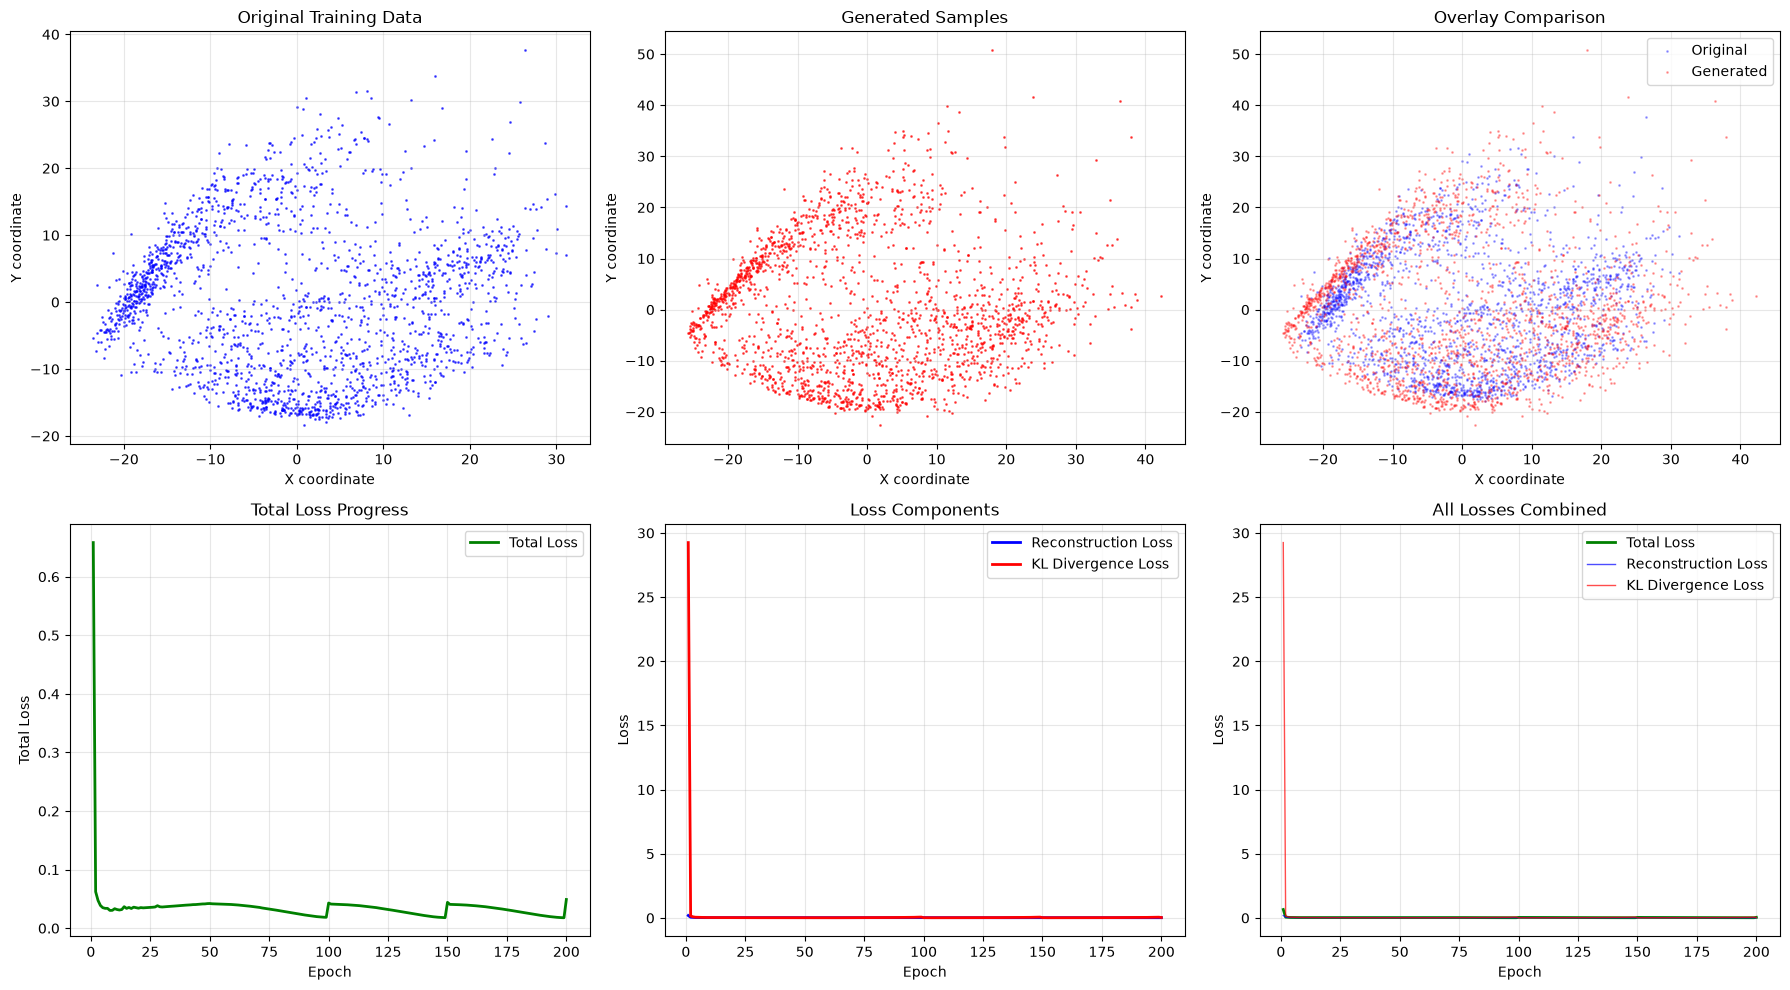

In [10]:
# Training loop
print("🎯 Starting VAE training...")
print("=" * 60)

# Lists to track training progress
total_losses = []
recon_losses = []
kl_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")
visualize_training_progress(0, [], [], [], save_plot=True)

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch
    avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta = train_epoch(epoch)
    
    # Track losses
    total_losses.append(avg_total_loss)
    recon_losses.append(avg_recon_loss)
    kl_losses.append(avg_kl_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=True)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Total Loss: {avg_total_loss:.4f}")
    print(f"   Reconstruction Loss: {avg_recon_loss:.4f}")
    print(f"   KL Divergence Loss: {avg_kl_loss:.4f}")
    print(f"   Beta: {current_beta:.3f}")
    print(f"   Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained model
torch.save(vae.state_dict(), 'models/vae_model.pth')
print("💾 Model saved as 'vae_model.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, total_losses, recon_losses, kl_losses, save_plot=True)


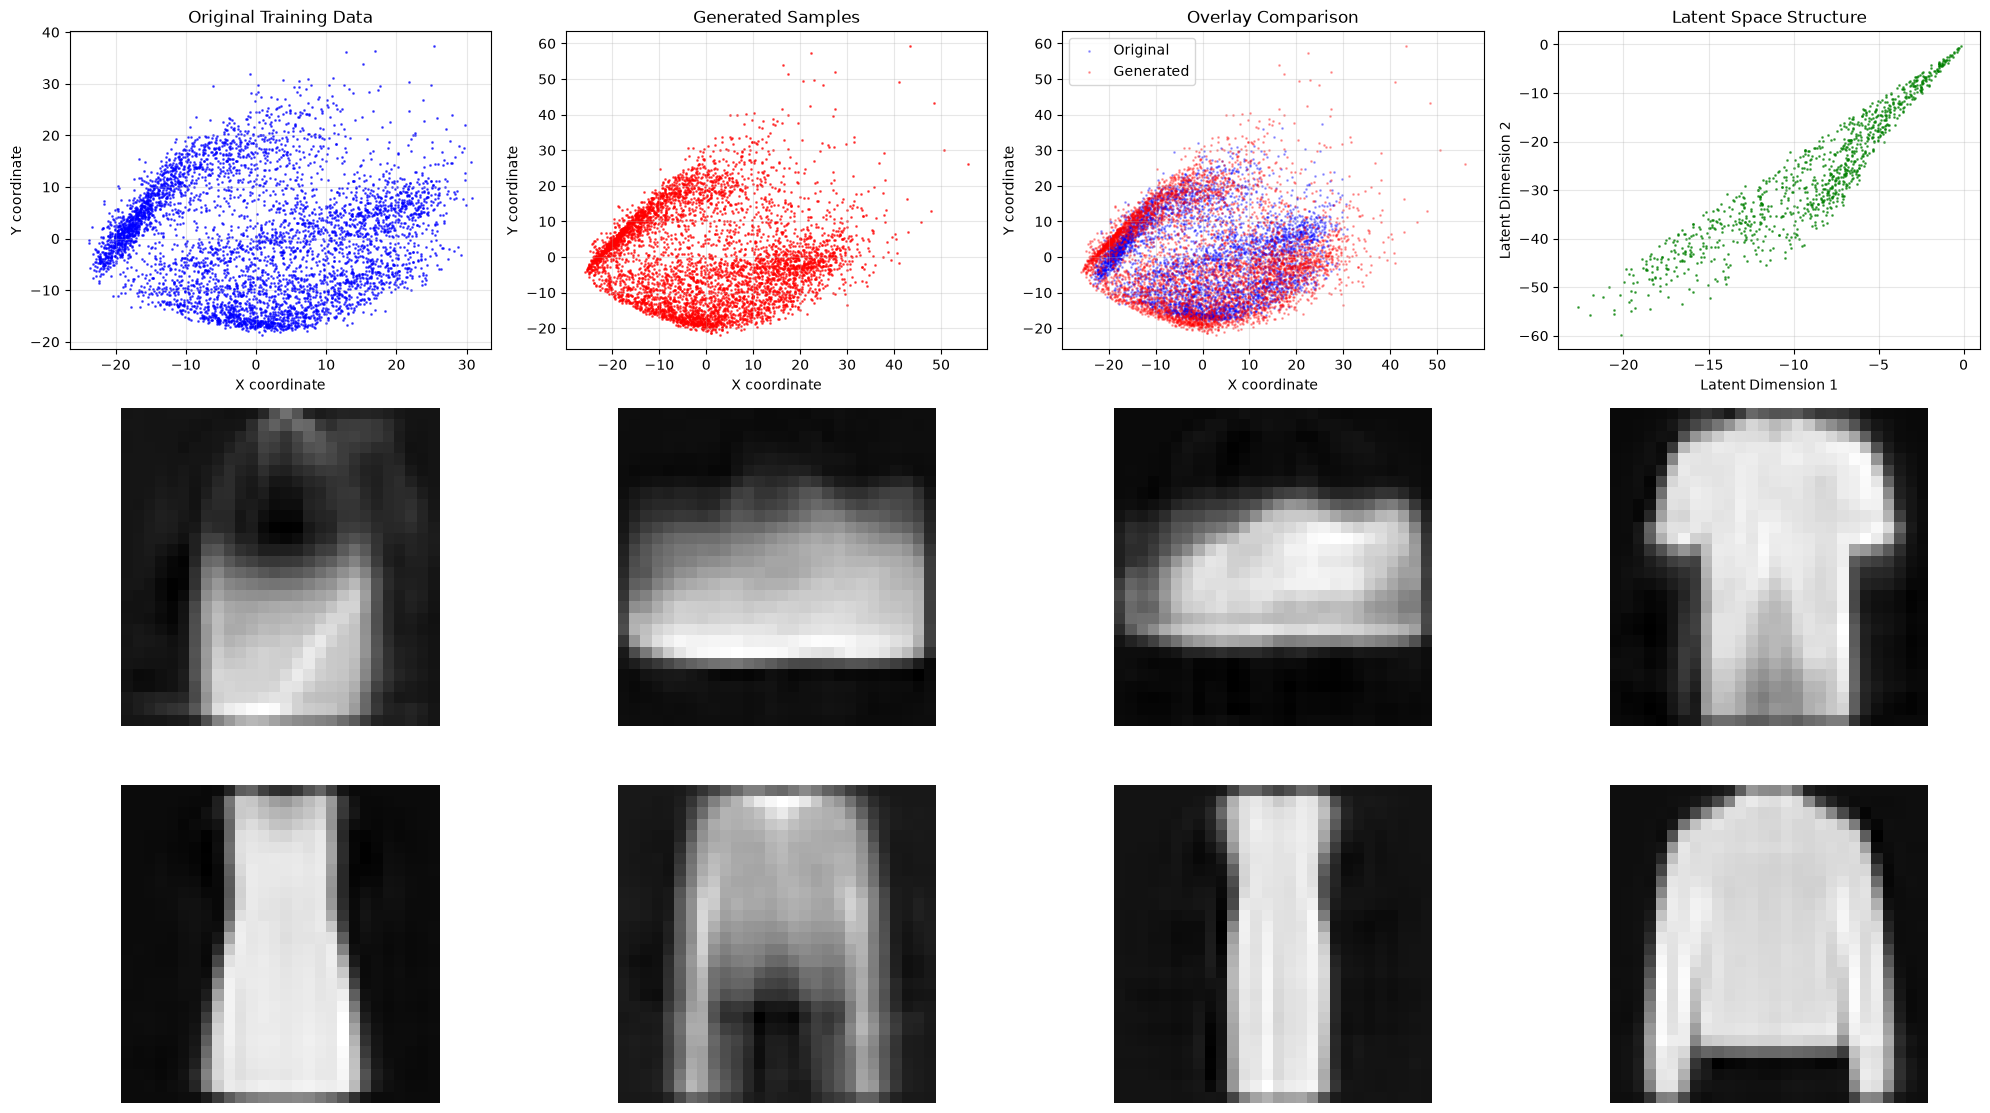

In [13]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 4, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 4, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 4, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)

# Show the latent space structure
plt.subplot(4, 4, 4)
# Encode some real data to see latent space
vae.eval()
with torch.no_grad():
    train_data_reshaped = np.reshape(train_data.data[:1000], [1000, INPUT_DIM])
    mu, logvar = vae.encode(train_data_reshaped.to(device).float())
    latent_points = mu.cpu().numpy()

plt.scatter(latent_points[:, 0], latent_points[:, 1], c='green', s=1, alpha=0.6)
plt.title('Latent Space Structure')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.grid(True, alpha=0.3)


for i in range(8):
    plt.subplot(4, 4, 4 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Change learning rate (try 1e-4, 1e-2)
   - Modify network sizes (try 128, 512 hidden units)
   - Adjust beta parameter (try 0.1, 2.0, 10.0)
3. **Visualize Training**: Watch how the latent space evolves during training

### Intermediate Experiments:
4. **Different Latent Dimensions**: Try 1D, 3D, or 4D latent spaces
5. **Beta-VAE**: Experiment with different beta values to control disentanglement
6. **Conditional VAE**: Generate different types of data based on labels

### Advanced Experiments:
7. **Higher Dimensions**: Apply to image data (MNIST, CIFAR-10)
8. **WAE (Wasserstein Autoencoder)**: Implement the Wasserstein variant
9. **VAE-GAN**: Combine VAE with GAN for better generation quality

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
LATENT_DIM = 4         # Higher dimensional latent space
HIDDEN_DIM = 512       # Larger networks

# Try different beta values
BETA = 0.1             # Less regularization
BETA = 10.0            # More regularization
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **Original VAE Paper**: "Auto-Encoding Variational Bayes" by Kingma & Welling (2014)
2. **Beta-VAE**: "β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework" by Higgins et al. (2017)
3. **WAE**: "Wasserstein Auto-Encoders" by Tolstikhin et al. (2018)
4. **VAE-GAN**: "Autoencoding beyond pixels using a learned similarity metric" by Larsen et al. (2016)

### Libraries to Explore:
- **PyTorch Lightning**: For easier VAE training
- **Hugging Face Transformers**: For text-based VAEs
- **Pyro**: Probabilistic programming with VAEs

### Applications:
- **Image Generation**: Creating new images from scratch
- **Data Compression**: Learning efficient representations
- **Anomaly Detection**: Finding unusual patterns in data
- **Data Augmentation**: Generating more training data
- **Representation Learning**: Learning useful features for downstream tasks

### Key Takeaways:
- VAEs are powerful tools for generative modeling and representation learning
- The reparameterization trick is crucial for training
- The beta parameter controls the trade-off between reconstruction and regularization
- VAEs provide a principled way to learn continuous latent representations
- The latent space can be used for interpolation and manipulation

### Common VAE Challenges:
- **Blurry Reconstructions**: VAEs tend to produce smoother, less sharp outputs
- **Posterior Collapse**: When the latent space becomes uninformative
- **Beta Tuning**: Finding the right balance between reconstruction and regularization
- **Evaluation**: Measuring VAE quality objectively

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new about how VAEs work!*
